# Modelling Viewcount growth of movies post 2000

Inspired by the works of Richier et al.[cite], we adapt the bio-inspired modeling and apply it to user review data from the MovieLens dataset [cite]. Instead of treating popularity as a static metric, we investigate the evolution of views through cumulative time series. This enables us to analyze the underlying popularity mechanisms and categorize movies in too viral vs non-viral growth. 

We start out with an in-depth analysis of the dynamics of the top 500 most reviewed movies released post-2000, and then expand our investigation to the top 4,000 movies from post 2000 era.
The year 2000 was choosen arbitrarily as a cutoff to mitigate outliers and anomalys. Because the review plattform was established around 1996, the reviews published can not accuratly model the popularity of movies released prior to this. The choosen cutoff ensures that all movies that are part of our investigation are accurately captured in their populairty across their full lifetime.

In the following we will use the folowing metrics used by Richier et. al [cite]

|Modell Name|Population|Growth|Function|
|---|---|---|---|
|Logistic model|Fixed target population|Viral|$S(t) = \frac{M}{1 + \left(\frac{M - S(0)}{S(0)}\right) e^{-\lambda t}}$|
|Gompertz model|Fixed target population|Viral|$S(t) = M \exp\left(-\log\left(\frac{M}{S(0)}\right) \exp(-\lambda t)\right)$|
|Negative exponential model|Fixed target population|Non-viral|$S(t) = S(0) + (M - S(0))(1 - e^{-\lambda t})$|
|Linear model|Growing target population|Non-viral|$S(t) = S(0) + kt$|
|Modified negative exponential model|Growing target population|Non-viral|$S(t) = S(0) + (M - S(0))(1 - e^{-\lambda t}) + kt$|
|Modified Gompertz model|Growing target population|Viral|$S(t) = M \exp\left(-\log\left(\frac{M}{S(0)}\right) \exp(-\lambda t)\right) + kt$|

## Preliminary analysis
The analysis starts of with an indepth analysis of the top 500 most rated movies post 2000.

In [7]:
import pandas as pd
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt


TOP_N = 500

In [2]:
movies_dtype = {
    "movieId": "int32",
    "title": "string",
    "genres": "string"
}
ratings_dtype = {
    "userId": "int32",
    "movieId": "int32",
    "rating": "float32",
    "timestamp": "int64"
}
movies_df = pd.read_csv("./../data/ml-latest/movies.csv", dtype=movies_dtype)               # Load df with explicit datatypes
ratings_df = pd.read_csv("./../data/ml-latest/ratings.csv", dtype=ratings_dtype)            #

movies_df["year"] = movies_df["title"].str.extract(r"\((\d{4})\)").astype("Int64")          # Add coll for release year based on () in name
recent_movies = movies_df[movies_df["year"] >= 2000].copy()


recent_movie_ids = recent_movies["movieId"]                                                 # Filter the movies so only >2000 and in top 500 most reviews remain
review_counts = ratings_df["movieId"].value_counts()
review_counts.head()
recent_movie_review_counts = review_counts[review_counts.index.isin(recent_movie_ids)]

top_movie_ids = recent_movie_review_counts.nlargest(TOP_N).index.values

# Filter the movies
movies_df = recent_movies[recent_movies["movieId"].isin(top_movie_ids)]
ratings_df = ratings_df[ratings_df["movieId"].isin(top_movie_ids)]

In [3]:
movie_time_series = {}

for movie_id in movies_df["movieId"]:                                                           # Convert all reviews into a normalized timeseries
    movie_ratings = ratings_df[ratings_df["movieId"] == movie_id].sort_values("timestamp")
    timestamps = movie_ratings["timestamp"].values


    elapsed_time = timestamps - timestamps[0]
    total_time = elapsed_time[-1]

    cumulative_counts = np.arange(1, len(movie_ratings) + 1, dtype=float)
    max_count = cumulative_counts[-1]

    t_norm = elapsed_time / total_time if total_time > 0 else elapsed_time
    y_norm = cumulative_counts / max_count

    movie_time_series[movie_id] = {
        "title": movies_df.loc[movies_df["movieId"] == movie_id, "title"].values[0],
        "t": t_norm,
        "y": y_norm,
        "total_reviews": max_count,
        "avg_rating": movie_ratings["rating"].mean()
    }

In [14]:
# Viral, Fixed Target Population                                        # Define all our models
def logistic(t, lam, S0):
    M = 1.0
    return M/(1+((M-S0)/S0)*np.exp(-lam*M*t))

def gompertz(t, lam, S0):
    M = 1.0
    return M*np.exp(-np.log(M/S0)*np.exp(-lam*t))

# Non-viral, Fixed target population
def neg_exponential(t, lam, S0):
    M = 1.0
    return S0 + (M - S0) * (1.0 - np.exp(-lam * t))

# Non-viral, Growing target population
def linear(t, lam, S0):
    return S0 + lam * t

def mod_neg_exponential(t, lam, k, S0):
    M = 1.0
    return S0 + (M - S0) * (1.0 - np.exp(-lam*t)) + k * t

# Viral, Growing target population
def mod_gompertz(t, lam, k, S0):
    M = 1.0
    return M * np.exp(-np.log(M / S0) * np.exp(-lam * t)) + k * t

def one_par_wrapper(model_func, S0):                                    # Wrapper function so we can use Scipy.optimize.curvefit
    def wrapped_model(t, lam):
        return model_func(t, lam, S0)
    return wrapped_model

def two_par_wrapper(model_func, S0):
    def wrapped_model(t, lam, k):
        return model_func(t, lam, k, S0)
    return wrapped_model

models = {
    "Linear":linear,
    "Logistic": logistic,
    "Gompertz": gompertz,
    "Negative Exponential": neg_exponential,
    "Mod. Neg. Exponential": mod_neg_exponential,
    "Mod. Gompertz": mod_gompertz,
}

def get_best_fit(t_vals, y_vals, models, one_par_wrapper, two_par_wrapper):                 # i just factored out my function fitting to keep code atleast a little clean
    n = len(y_vals)
    if n == 0:
        return {"name": "Unclassified (No Data)", "mer": None, "gof": None, "msc": None, "lam": None, "k": None}

    S0 = y_vals[0] if y_vals[0] > 0 else 1e-5
    candidates = []

    for model_name, model_func in models.items():
        try:
            if model_name in ["Mod. Neg. Exponential", "Mod. Gompertz"]:
                wrapped_func = two_par_wrapper(model_func, S0)
                p0 = [1.0, 0.1]     # initial guess for lam and k
                p = 2
                popt, _ = curve_fit(wrapped_func, t_vals, y_vals, p0=p0, method="lm")
                opt_lam, opt_k = popt
                y_pred = wrapped_func(t_vals, opt_lam, opt_k)
                p = 2
            else:
                wrapped_func = one_par_wrapper(model_func, S0)

                popt, _ = curve_fit(wrapped_func, t_vals, y_vals, p0=[1.0], method="lm")
                p0 = [1.0]          # initial guess for lam
                p = 1
                opt_lam = popt
                opt_k = None
                y_pred = wrapped_func(t_vals, opt_lam)
                p = 1

            mer = np.mean(np.abs(y_vals - y_pred) / (y_vals + 1.0))
            msc = np.sum((y_pred - y_vals) ** 2)
            df = n - p
            if df > 0:
                gof = (1.0/df) * msc
            else:
                gof = float("inf")
            
            candidates.append({"name": model_name, "mer": mer, "msc": msc, "gof": gof, "lam": opt_lam, "k": opt_k})
        except Exception:
            continue

    if not candidates:
        return {"name": "Unclassified (Fit Failed)", "mer": None, "gof": None, "msc": None, "lam": None, "k": None}

    return min(candidates, key=lambda x: x["gof"])

In [15]:
results = []

for movie_id, data in movie_time_series.items():
    best = get_best_fit(data["t"], data["y"], models, one_par_wrapper, two_par_wrapper)

    results.append({
        "movieId": movie_id,
        "title": data["title"],
        "total_reviews": data["total_reviews"],
        "avg_rating": data["avg_rating"],
        "best_model": best["name"],
        "MER": best["mer"],
        "GOF": best["gof"],
        "MSC": best["msc"],
        "opt_lam": best["lam"],
        "opt_k": best["k"]
    })

df_results = pd.DataFrame(results)
print(df_results["best_model"].value_counts())

/tmp/ipykernel_24727/1749490021.py:61: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, _ = curve_fit(wrapped_func, t_vals, y_vals, p0=p0, method="lm")


best_model
Mod. Neg. Exponential    259
Mod. Gompertz            213
Gompertz                  25
Negative Exponential       1
Linear                     1
Logistic                   1
Name: count, dtype: int64


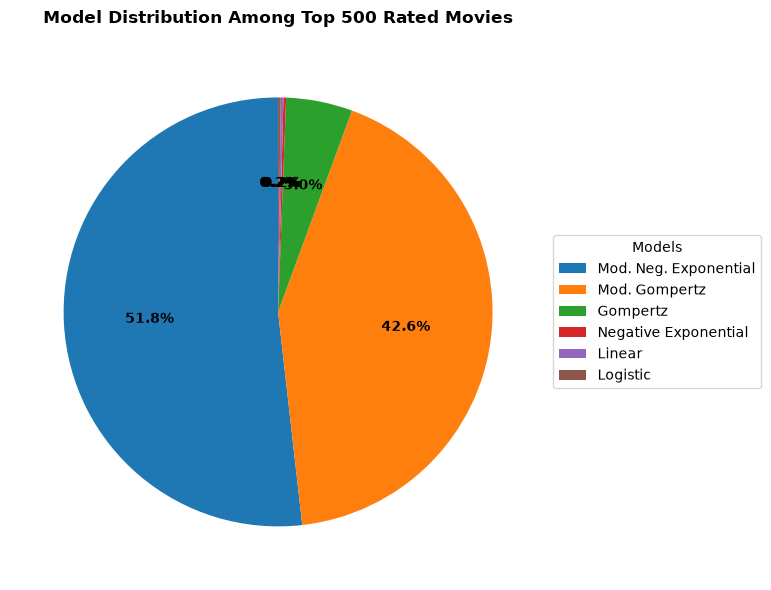

In [16]:
model_counts = df_results["best_model"].value_counts()

fig, ax = plt.subplots(figsize=(8, 6), dpi=100)

wedges, texts, autotexts = ax.pie(
    model_counts.values,
    autopct='%1.1f%%',
    startangle=90,
    textprops=dict(fontsize=10)
)

plt.setp(autotexts, size=10, weight="bold", color="black")

ax.legend(
    wedges, 
    model_counts.index, 
    title="Models", 
    loc="center left", 
    bbox_to_anchor=(1, 0, 0.5, 1)
)

ax.set_title(f"Model Distribution Among Top {TOP_N} Rated Movies", fontsize=12, fontweight="bold", pad=15)
plt.tight_layout()

The classification for the top 500 movies successfully converges across all evaluated films. Comparing our results to the results of Richier et al. [cite] gives us some intersting insights. Modified Negative Exponential and Modified Gompertz are by far the dominant categories, containing 94,4% of the classified movies. However, unlike the results in the paper, all other classes are almost non existing in our analysis, with three models only having a single movie.

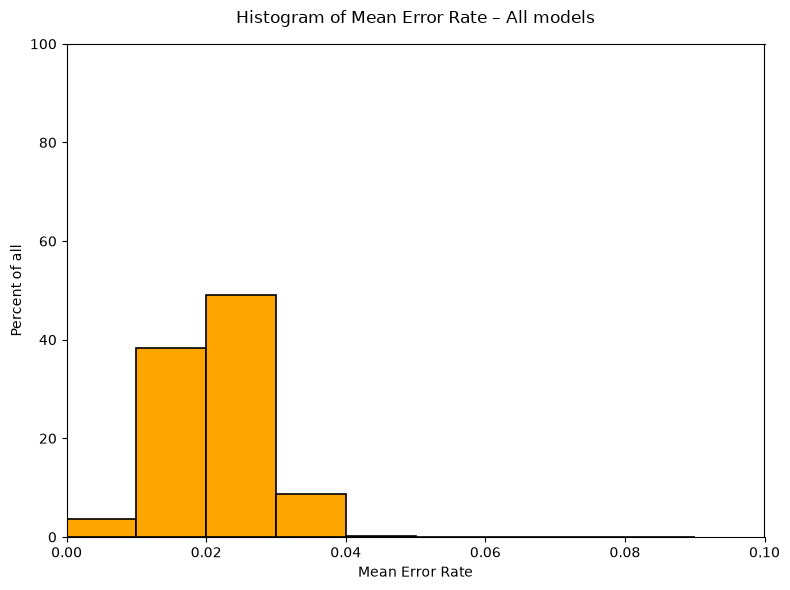

In [ ]:
mer_data = df_results["MER"].dropna().values

bins = np.arange(0.0, 0.1, 0.01)

fig, ax = plt.subplots(figsize=(8, 6), dpi=100)

weights = np.ones(len(mer_data)) / len(mer_data) * 100

ax.hist(
    mer_data,
    bins=bins,
    weights=weights,
    color="orange",
    edgecolor="black",
    linewidth=1.2,
)

ax.set_title("Histogram of Mean Error Rate – All models", fontsize=12, pad=15)
ax.set_xlabel("Mean Error Rate", fontsize=10)
ax.set_ylabel("Percent of all", fontsize=10)

ax.set_xlim(0.00, 0.1)
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

Looking into the mean eror rate (MER) distribution we see that almost all our movies are categorized with a MER lower than 0.05. suggesting that our models fit extremly well and capture the popularity dynamics sufficeintly well. However, the paper introduces a second more finegrained metric to asses the quality of our models. The Goodness of Fit (GOF), calculates how well our modelled functions capture the underlying data. With lower numbers coresponding to a better fit.

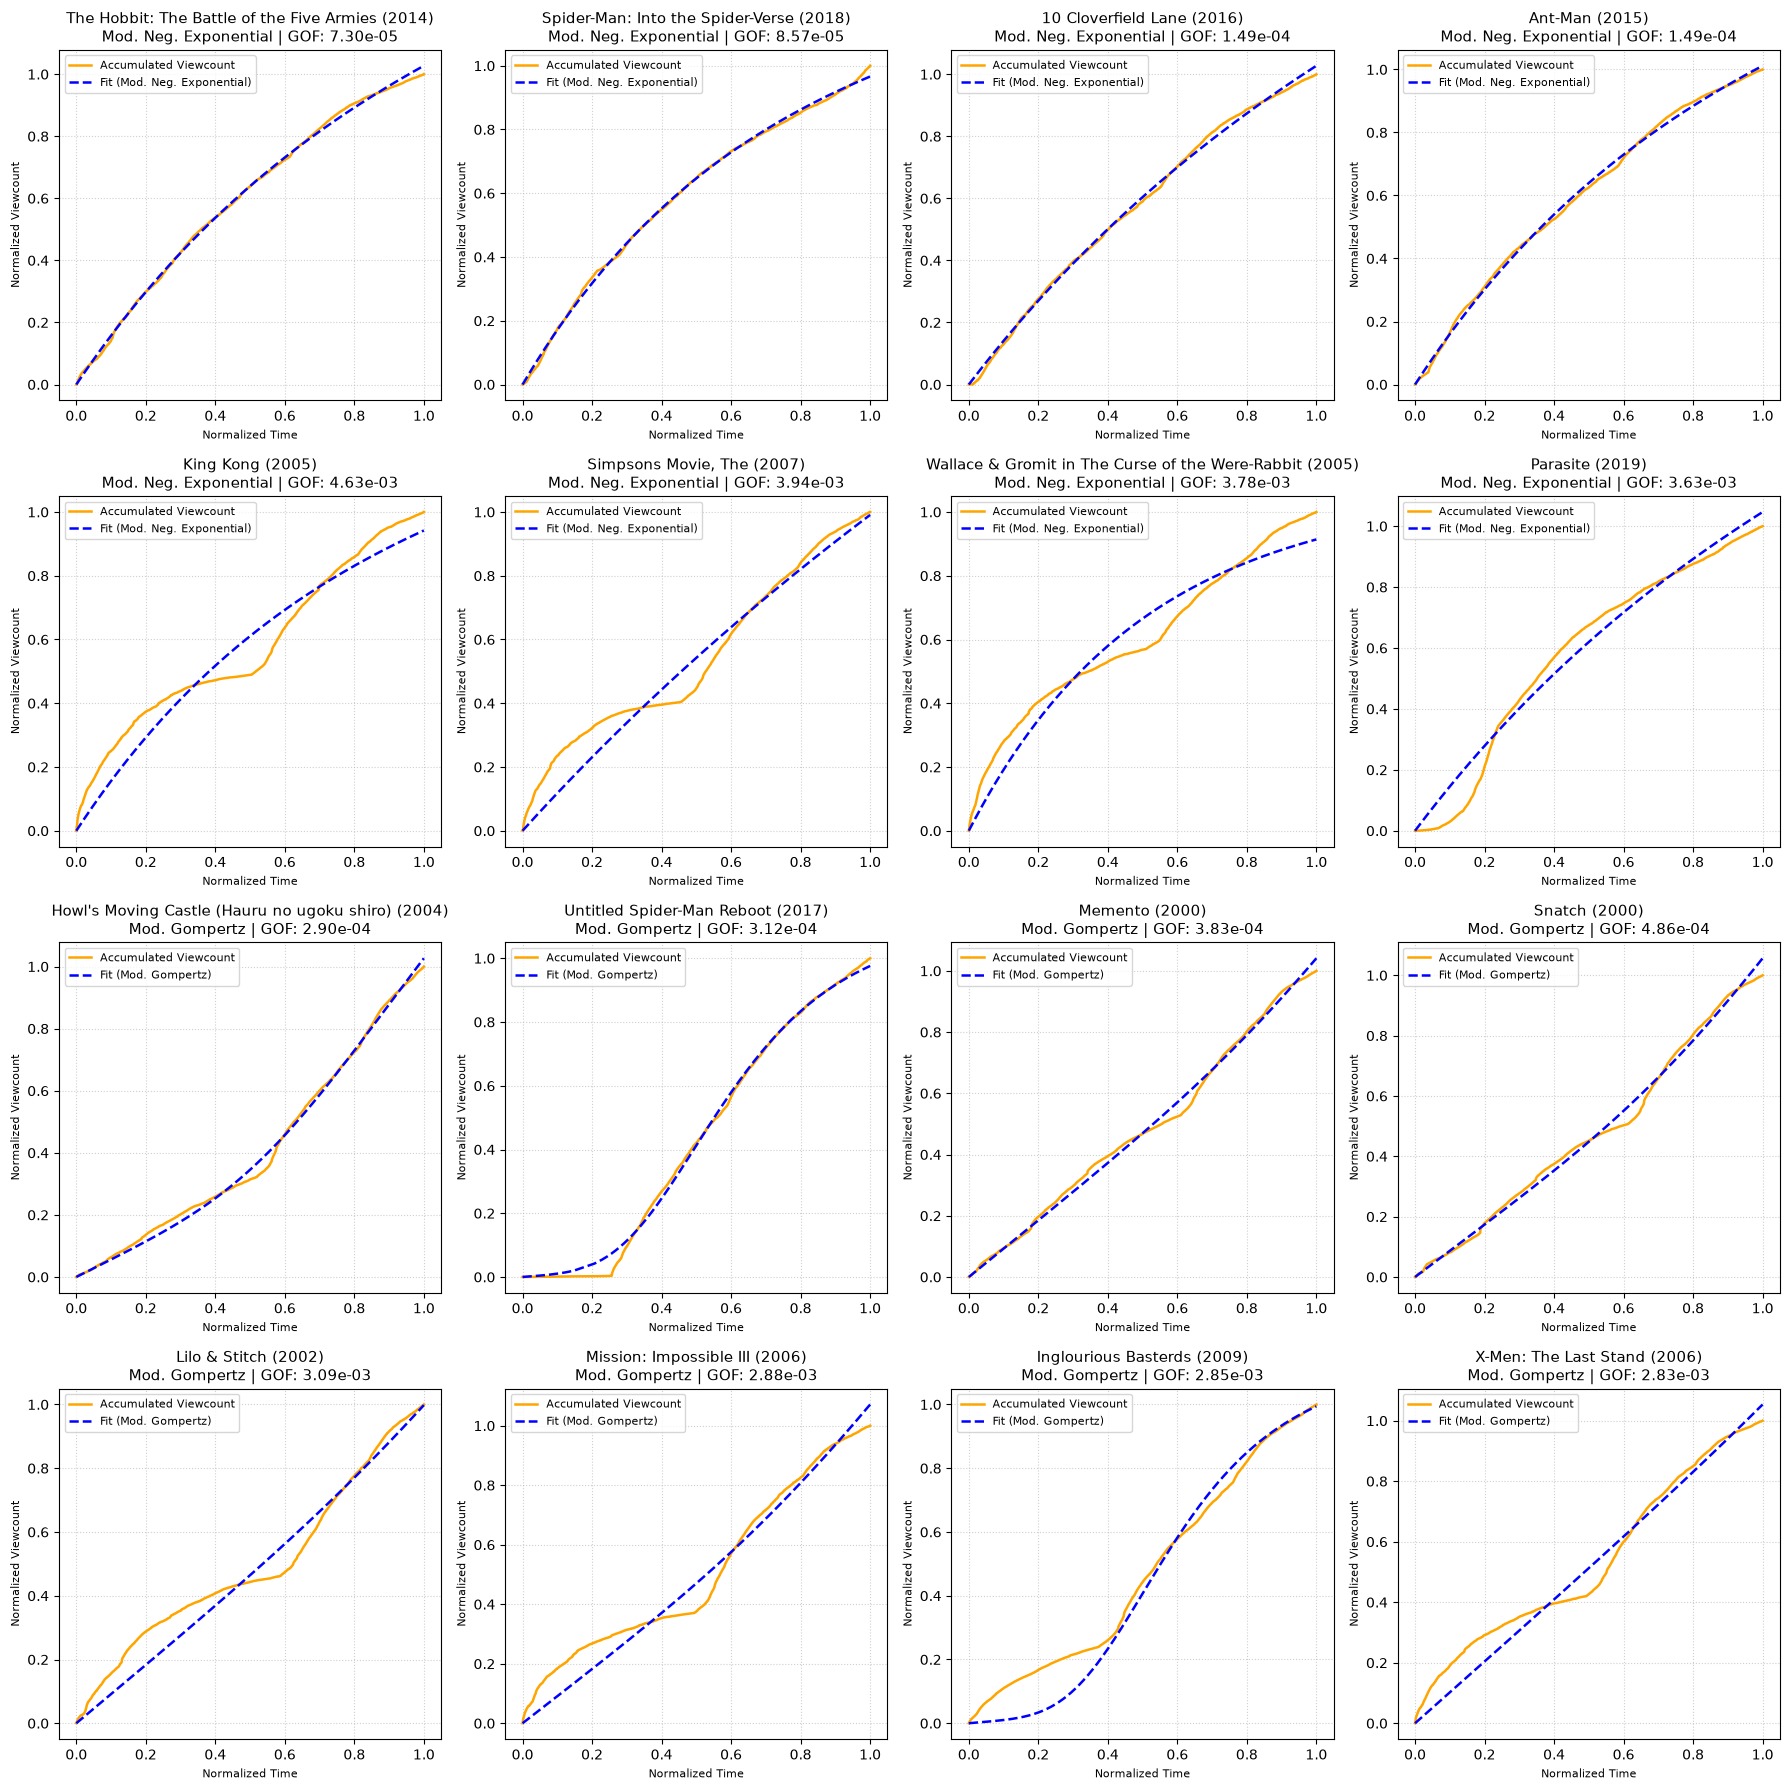

In [17]:
# Looking at the curves view counts of Mod Neg Exponential and Mod Gompertz

neg_exponential_best = (
    df_results[df_results["best_model"] == "Mod. Neg. Exponential"]
    .sort_values(by="GOF", ascending = True)       # Lowest GOF best fit
    .head(4)
)

neg_exponential_worst = (
    df_results[df_results["best_model"] == "Mod. Neg. Exponential"]
    .sort_values(by="GOF", ascending = False)       # Lowest GOF best fit
    .head(4)
)

mod_gom_best = (
    df_results[df_results["best_model"] == "Mod. Gompertz"]
    .sort_values(by="GOF", ascending = True)       # Lowest GOF best fit
    .head(4)
)

mod_gom_worst = (
    df_results[df_results["best_model"] == "Mod. Gompertz"]
    .sort_values(by="GOF", ascending = False)       # Lowest GOF best fit
    .head(4)
)

plot_df = pd.concat([
    neg_exponential_best, 
    neg_exponential_worst, 
    mod_gom_best, 
    mod_gom_worst
], ignore_index=True)

fig, axes = plt.subplots(4, 4, figsize=(18, 18))
axes = axes.flatten()
for idx, (_, row) in enumerate(plot_df.iterrows()):
    movie_id = row["movieId"]
    model_name = row["best_model"]
    title = row["title"]
    lam = row["opt_lam"]
    k = row["opt_k"]

    data = movie_time_series[movie_id]
    t_vals = data["t"]
    y_vals = data["y"]
    S0 = y_vals[0] if y_vals[0] > 0 else 1e-5

    ax = axes[idx]
    ax.plot(t_vals, y_vals, label="Accumulated Viewcount", color="orange", linewidth=1.8)

    model_func = models[model_name]
    wrapped_func = two_par_wrapper(model_func, S0)
    y_pred = wrapped_func(t_vals, lam, k)

    ax.plot(t_vals, y_pred, label=f"Fit ({model_name})", color="blue",linestyle="dashed" ,linewidth=1.8)
    
   

    ax.set_title(f"{title}\n{model_name} | GOF: {row['GOF']:.2e}", fontsize=11)
    ax.set_xlabel("Normalized Time", fontsize=8)
    ax.set_ylabel("Normalized Viewcount", fontsize=8)
    ax.legend(fontsize=8)
    ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()

After looking at the 4 best and worst results of modified negative xponential and modified gompertzt according to the GOF, we can conclude that for some movies our model captures the popularity dynamic extremly well and sufficiently good. however looking at our worst cases, reveals that for some movies we see a ratehr distinct number of peeks. most often two. This suggest that movie popularity unlike the studied youtube videos is much more complex. Over the lifetime of a movie it experiences multiple spikes in popularity, coinciding with an increase in user reviews in our dataset. These multiple peeks can not accuratly be captured by any of our models. 

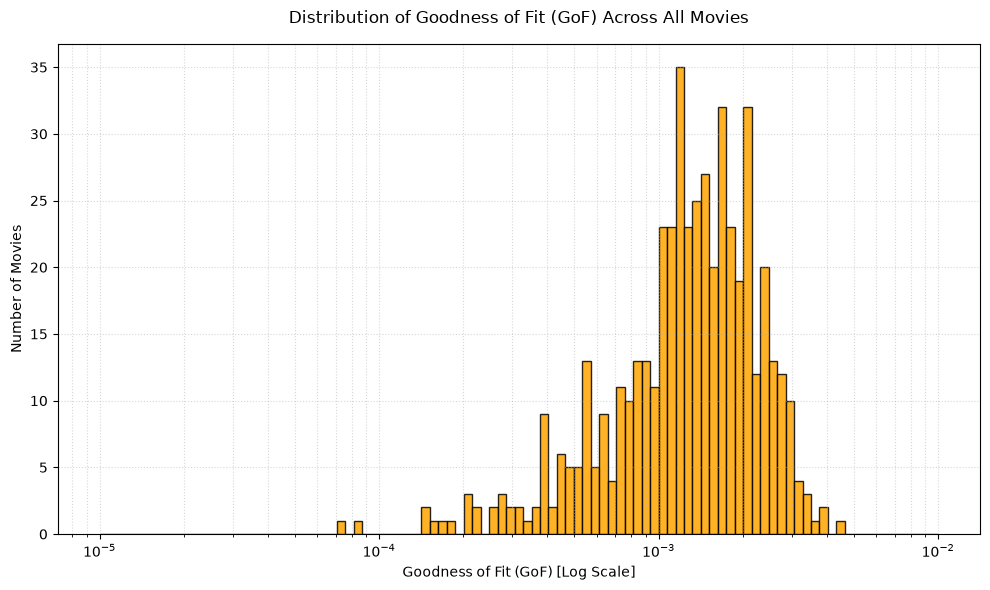

In [ ]:
gof_values = df_results["GOF"].values

min_log = np.floor(np.log10(gof_values.min()))
max_log = np.ceil(np.log10(gof_values.max()))
log_bins = np.logspace(min_log, max_log, 100)

fig, ax = plt.subplots(figsize=(10, 6), dpi=100)

ax.hist(
    gof_values,
    bins=log_bins,
    edgecolor="black",
    linewidth=1.0,
    alpha=0.85,
    color="orange"
)

ax.set_xscale("log")
ax.set_title("Distribution of Goodness of Fit (GoF) Across All Movies", fontsize=12, pad=15)
ax.set_xlabel("Goodness of Fit (GoF) [Log Scale]", fontsize=10)
ax.set_ylabel("Number of Movies", fontsize=10)
ax.grid(True, which="both", linestyle=":", alpha=0.5)

plt.tight_layout()

looking at the distribution of the GOF across all our movies shows that movies in fact seem not to bes as accuratly captured by our bio inspired approach.
Compared to the GOF resutls from the paper, instead of most movies being comfortably below 10^-3 most of our movies have score worse than 10^-3 which is a stark difference to the papper resutls. However, this does not prevent us to fully analze our genrated data further.

# Predictive Quality
One of the most interesting parts of the original work was the investigation of predictive quality. We follow a similar investigation. We take the first 50% of a movies lifetime data, and then find the best model for it. we then compare our prediction with the actual data and see for how many movie our prediction stay belwo the threshold of MER < 0.05, which was choosen in the paper

In [20]:
prediction_results = []

for movie_id, data in movie_time_series.items():
    t_vals = data["t"]
    y_vals = data["y"]
    n_total = len(y_vals)
    
    
    if n_total < 10:                    # Makinf sure we have atleast a few reviews, should be no problem for top 500
        continue
    
    split_idx = n_total // 2
    
    t_train, y_train = t_vals[:split_idx], y_vals[:split_idx]
    t_test, y_test = t_vals[split_idx:], y_vals[split_idx:]
    
    if len(t_train) < 3 or len(t_test) < 3:
        continue

    best = get_best_fit(t_train, y_train, models, one_par_wrapper, two_par_wrapper)
    
    if best["gof"] is None or best["name"].startswith("Unclassified"):
        continue

    best_model_name = best["name"]
    best_lam = best["lam"]
    best_k = best["k"]

    S0_global = y_vals[0] if y_vals[0] > 0 else 1e-5
    
    if best_model_name in ["Mod. Neg. Exponential", "Mod. Gompertz"]:
        wrapped_func_test = two_par_wrapper(models[best_model_name], S0_global)
        y_pred_test = wrapped_func_test(t_test, best_lam, best_k)
    else:
        wrapped_func_test = one_par_wrapper(models[best_model_name], S0_global)
        y_pred_test = wrapped_func_test(t_test, best_lam)

    test_mer = np.mean(np.abs(y_test - y_pred_test) / (y_test + 1.0))
    test_msc = np.sum((y_test - y_pred_test) ** 2)

    prediction_results.append({
        "movieId": movie_id,
        "title": data["title"],
        "selected_model": best_model_name,
        "test_MER": test_mer,
        "test_MSC": test_msc,
        "is_accurate": test_mer <= 0.05
    })

predictions_df = pd.DataFrame(prediction_results)

if not predictions_df.empty:
    success_rate = predictions_df['is_accurate'].mean() * 100
    print(f"\nPercentage of movies predicted with <= 5% MER on the second half: {success_rate:.2f}%")

/tmp/ipykernel_24727/1749490021.py:61: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, _ = curve_fit(wrapped_func, t_vals, y_vals, p0=p0, method="lm")
/tmp/ipykernel_24727/1749490021.py:26: RuntimeWarning: overflow encountered in exp
  return M * np.exp(-np.log(M / S0) * np.exp(-lam * t)) + k * t
/tmp/ipykernel_24727/1749490021.py:26: RuntimeWarning: overflow encountered in multiply
  return M * np.exp(-np.log(M / S0) * np.exp(-lam * t)) + k * t



Percentage of movies predicted with <= 5% MER on the second half: 17.60%


We see we have only correctly predicted the future populairty for 17,60 % of movies. This is further evidencen that our models are not accuratly capturing the popularity over time

# Analyse movies in popularity classes
Another interesting point is grouping the movies into popularity classes.

Movies by Popularity Class:
popularity_bin
Very Unpopular (<100)      0
Unpopular (100-999)        0
Successful (1k-9.9k)     163
Popular (10k-99.9k)      337
Very Popular (100k+)       0
Name: count, dtype: int64


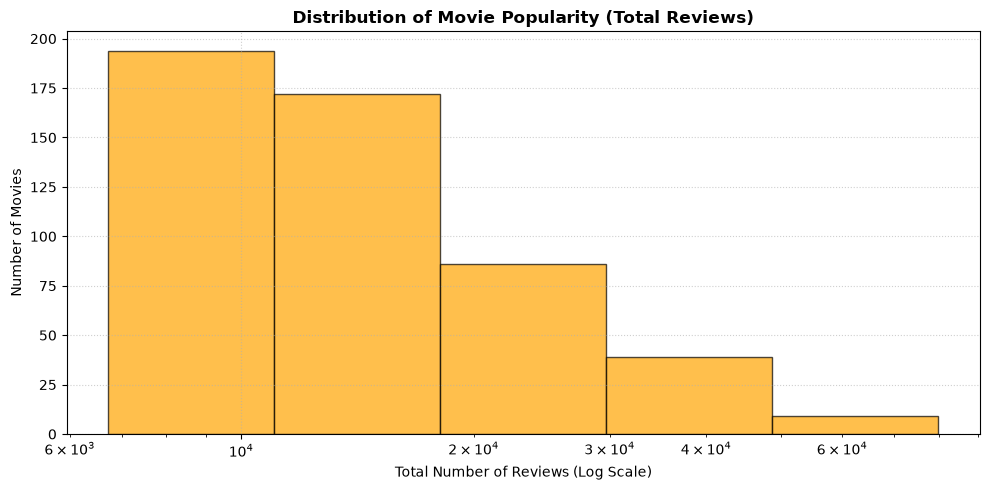

In [21]:
bin_edges = [0, 100, 1000, 10000, 100000, float("inf")]
bin_labels = [
    "Very Unpopular (<100)",
    "Unpopular (100-999)",
    "Successful (1k-9.9k)",
    "Popular (10k-99.9k)",
    "Very Popular (100k+)",
]

df_results["popularity_bin"] = pd.cut(
    df_results["total_reviews"], bins=bin_edges, labels=bin_labels, right=False
)

print("Movies by Popularity Class:")
print(df_results["popularity_bin"].value_counts(sort=False))

fig, ax = plt.subplots(figsize=(10, 5), dpi=100)

counts, edges, patches = ax.hist(
    df_results["total_reviews"].dropna(),
    bins=np.logspace(
        np.log10(max(1, df_results["total_reviews"].min())),
        np.log10(df_results["total_reviews"].max()),
        6,
    ),
    color="orange",
    edgecolor="black",
    alpha=0.7,
)

ax.set_xscale("log")
ax.set_title("Distribution of Movie Popularity (Total Reviews)", fontsize=12, fontweight="bold")
ax.set_xlabel("Total Number of Reviews (Log Scale)", fontsize=10)
ax.set_ylabel("Number of Movies", fontsize=10)
ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

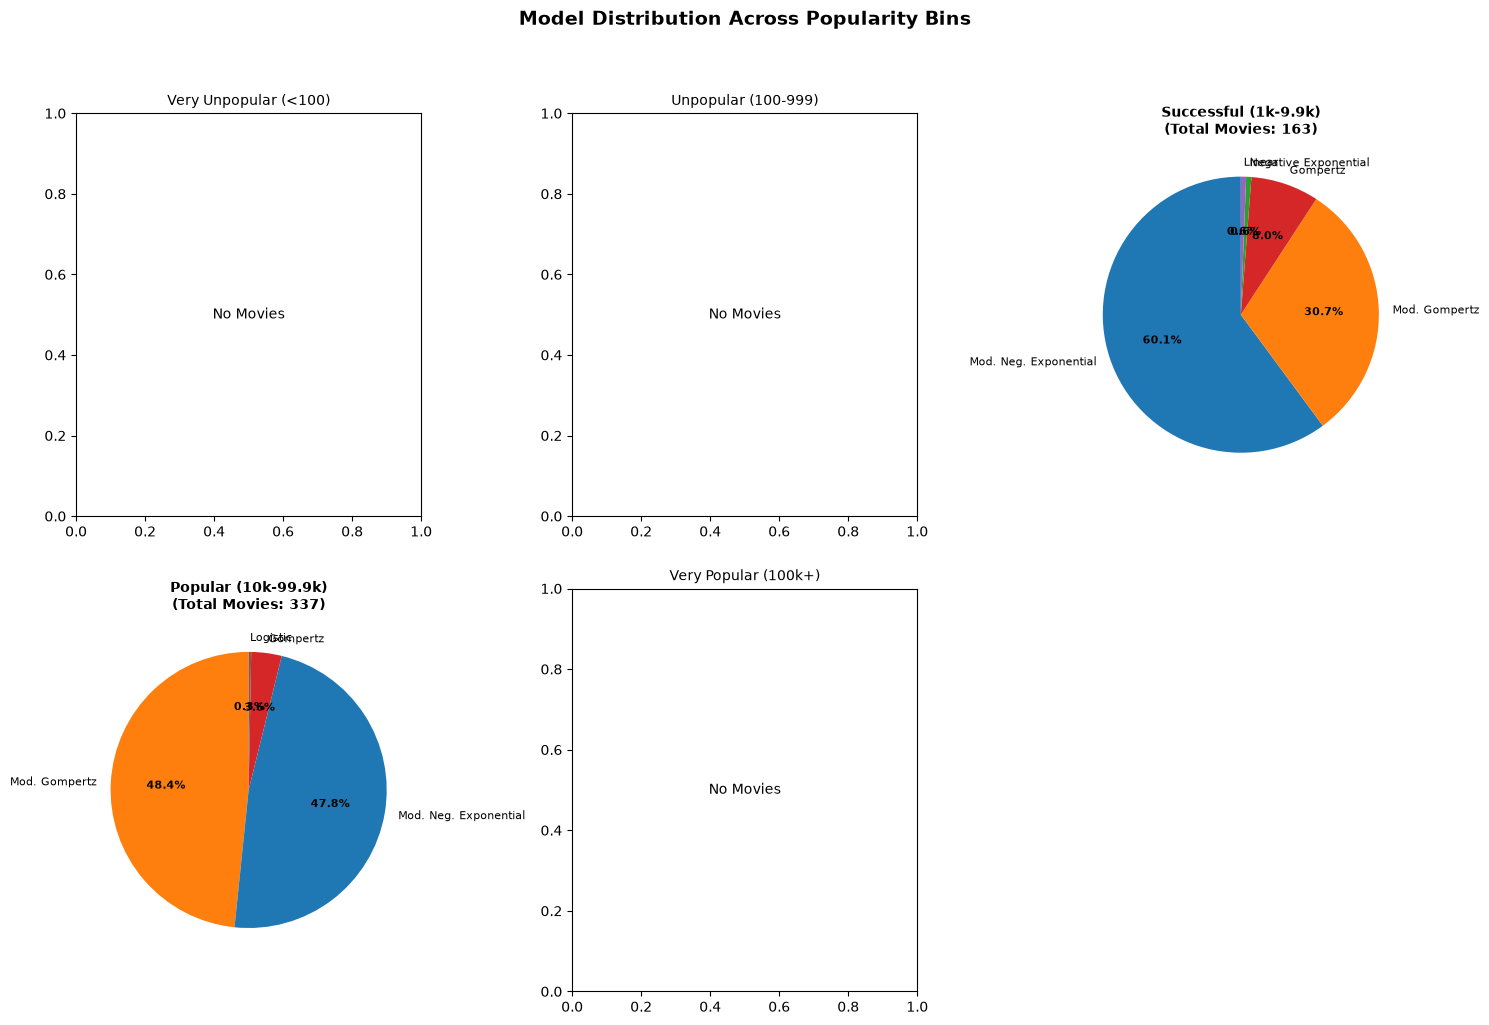

In [22]:
plot_df = df_results.dropna(subset=["popularity_bin", "best_model"])

bins_with_data = plot_df["popularity_bin"].dtype.categories

num_bins = len(bins_with_data)
if num_bins > 0:
    unique_models = plot_df["best_model"].unique()
    color_palette = plt.get_cmap("tab10").colors
    model_color_map = {
        model: color_palette[i % len(color_palette)] 
        for i, model in enumerate(unique_models)
    }

    cols = 3
    rows = (num_bins + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 5))
    if num_bins == 1:
        axes = np.array([axes])
    else:
        axes = axes.flatten()

    for idx, bin_name in enumerate(bins_with_data):
        ax = axes[idx]
        
        sub_df = plot_df[plot_df["popularity_bin"] == bin_name]
        model_counts = sub_df["best_model"].value_counts()
        
        if not model_counts.empty:
            bin_colors = [model_color_map[model] for model in model_counts.index]
            
            wedges, texts, autotexts = ax.pie(
                model_counts.values, 
                labels=model_counts.index, 
                colors=bin_colors,
                autopct='%1.1f%%', 
                startangle=90,
                textprops=dict(fontsize=8)
            )
            plt.setp(autotexts, size=8, weight="bold")
            ax.set_title(f"{bin_name}\n(Total Movies: {len(sub_df)})", fontsize=10, fontweight="bold")
        else:
            ax.text(0.5, 0.5, "No Movies", horizontalalignment='center', verticalalignment='center', transform=ax.transAxes)
            ax.set_title(f"{bin_name}", fontsize=10)

    for j in range(num_bins, len(axes)):
        axes[j].axis('off')

    plt.suptitle("Model Distribution Across Popularity Bins", fontsize=14, fontweight="bold", y=1.02)
    plt.tight_layout()
else:
    print("No data available in popularity bins to plot.")

We can see that for popular movies the sahre of viral movies increase from roughly 38% (gompertz and modified gompertz) to 50%. So amongst the most popular movies we see the share of ciral movies increase significantly. This suggest that to get a truly popular movie you can not relly simply on huge marketing campagnes and you need word far more a word of mouth viral spread to get a movie in this category.

# Find if the top 10% by rating movies are in which growth class
another intersting stat would be too look at the top movies by average rating. the top 10 movies

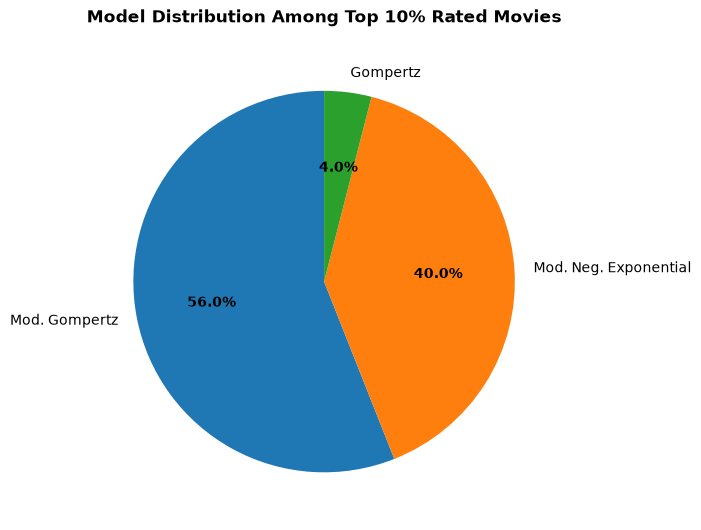

In [23]:
top_rated = df_results.sort_values(by="avg_rating", ascending=False).head(50)

model_counts = top_rated["best_model"].value_counts()

fig, ax = plt.subplots(figsize=(7, 7), dpi=100)

wedges, texts, autotexts = ax.pie(
    model_counts.values,
    labels=model_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    textprops=dict(fontsize=10)
)

plt.setp(autotexts, size=10, weight="bold")
ax.set_title("Model Distribution Among Top 10% Rated Movies", fontsize=12, fontweight="bold", pad=15)
plt.tight_layout()



We see the most popular models are 60% viral and only 40% are non viral growth patern movies

# Experiments using 10_000 movies after 2000

In [25]:
import pandas as pd
import numpy as np

TOP_N = 10_000

In [26]:
movies_dtype = {
    "movieId": "int32",
    "title": "string",
    "genres": "string"
}
ratings_dtype = {
    "userId": "int32",
    "movieId": "int32",
    "rating": "float32",
    "timestamp": "int64"
}
movies_df = pd.read_csv("./../data/ml-latest/movies.csv", dtype=movies_dtype)
ratings_df = pd.read_csv("./../data/ml-latest/ratings.csv", dtype=ratings_dtype)


# Fill in release year based on regex from title as col
movies_df["year"] = movies_df["title"].str.extract(r"\((\d{4})\)").astype("Int64")
recent_movies = movies_df[movies_df["year"] >= 2000].copy()


recent_movie_ids = recent_movies["movieId"]
review_counts = ratings_df["movieId"].value_counts()
review_counts.head()
recent_movie_review_counts = review_counts[review_counts.index.isin(recent_movie_ids)]

top_movie_ids = recent_movie_review_counts.nlargest(TOP_N).index.values

# Filter the movies
movies_df = recent_movies[recent_movies["movieId"].isin(top_movie_ids)]
ratings_df = ratings_df[ratings_df["movieId"].isin(top_movie_ids)]


print(f"Movies: {movies_df.shape}")
print(f"Ratings: {ratings_df.shape}")

Movies: (10000, 4)
Ratings: (13961279, 4)


In [27]:
movie_time_series = {}

for movie_id in movies_df["movieId"]:
    movie_ratings = ratings_df[ratings_df["movieId"] == movie_id].sort_values("timestamp")
    timestamps = movie_ratings["timestamp"].values


    elapsed_time = timestamps - timestamps[0]
    total_time = elapsed_time[-1]

    cumulative_counts = np.arange(1, len(movie_ratings) + 1, dtype=float)
    max_count = cumulative_counts[-1]

    t_norm = elapsed_time / total_time if total_time > 0 else elapsed_time
    y_norm = cumulative_counts / max_count

    movie_time_series[movie_id] = {
        "title": movies_df.loc[movies_df["movieId"] == movie_id, "title"].values[0],
        "t": t_norm,
        "y": y_norm,
        "total_reviews": max_count,
        "avg_rating": movie_ratings["rating"].mean()
    }

In [28]:
results = []

for movie_id, data in movie_time_series.items():
    best = get_best_fit(data["t"], data["y"], models, one_par_wrapper, two_par_wrapper)

    results.append({
        "movieId": movie_id,
        "title": data["title"],
        "total_reviews": data["total_reviews"],
        "avg_rating": data["avg_rating"],
        "best_model": best["name"],
        "MER": best["mer"],
        "GOF": best["gof"],
        "MSC": best["msc"],
        "opt_lam": best["lam"],
        "opt_k": best["k"]
    })

df_results = pd.DataFrame(results)
print(df_results["best_model"].value_counts())

/tmp/ipykernel_24727/1749490021.py:61: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, _ = curve_fit(wrapped_func, t_vals, y_vals, p0=p0, method="lm")


best_model
Mod. Neg. Exponential    7311
Mod. Gompertz            1147
Gompertz                  676
Negative Exponential      558
Logistic                  165
Linear                    143
Name: count, dtype: int64


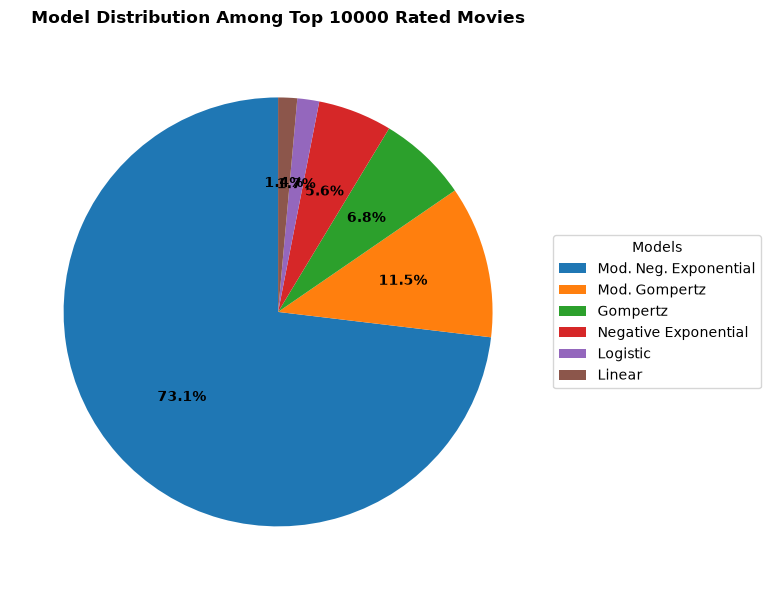

In [29]:
model_counts = df_results["best_model"].value_counts()

fig, ax = plt.subplots(figsize=(8, 6), dpi=100)

wedges, texts, autotexts = ax.pie(
    model_counts.values,
    autopct='%1.1f%%',
    startangle=90,
    textprops=dict(fontsize=10)
)

plt.setp(autotexts, size=10, weight="bold", color="black")

ax.legend(
    wedges, 
    model_counts.index, 
    title="Models", 
    loc="center left", 
    bbox_to_anchor=(1, 0, 0.5, 1)
)

ax.set_title(f"Model Distribution Among Top {TOP_N} Rated Movies", fontsize=12, fontweight="bold", pad=15)
plt.tight_layout()

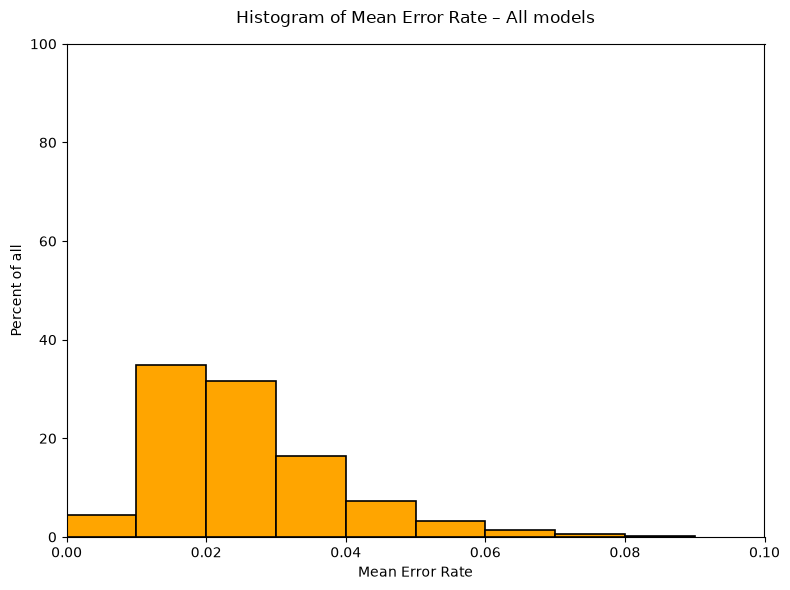

In [30]:
mer_data = df_results["MER"].dropna().values

bins = np.arange(0.0, 0.1, 0.01)

fig, ax = plt.subplots(figsize=(8, 6), dpi=100)

weights = np.ones(len(mer_data)) / len(mer_data) * 100

ax.hist(
    mer_data,
    bins=bins,
    weights=weights,
    color="orange",
    edgecolor="black",
    linewidth=1.2,
)

ax.set_title("Histogram of Mean Error Rate – All models", fontsize=12, pad=15)
ax.set_xlabel("Mean Error Rate", fontsize=10)
ax.set_ylabel("Percent of all", fontsize=10)

ax.set_xlim(0.00, 0.1)
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

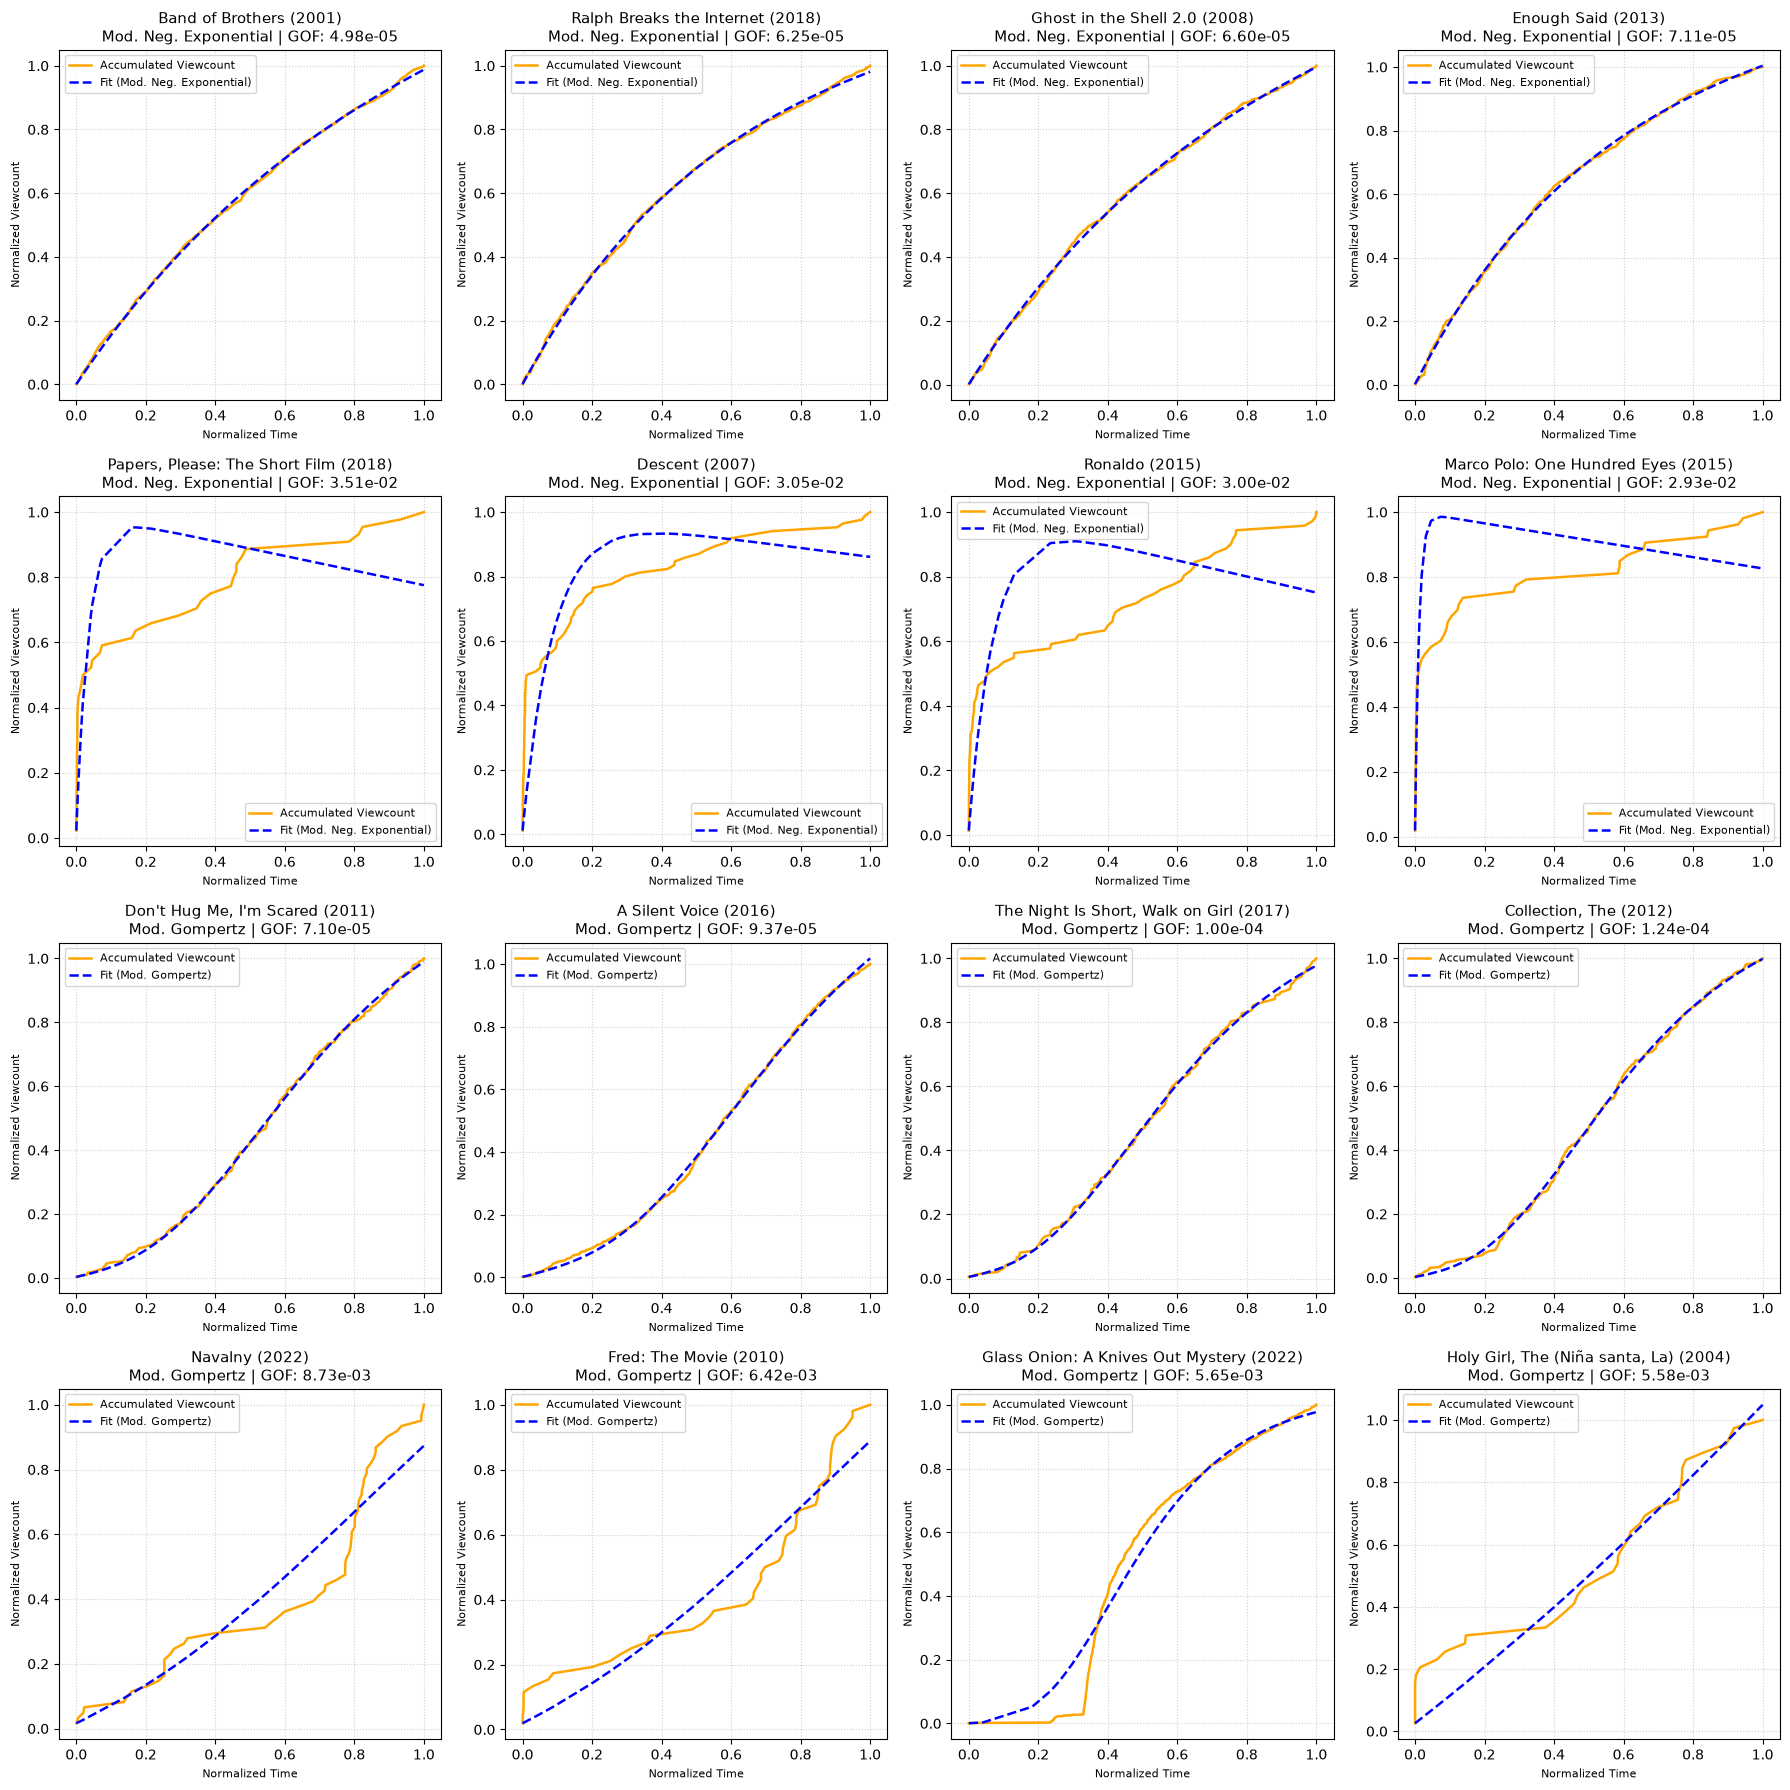

In [31]:
# Looking at the curves view counts of Mod Neg Exponential and Mod Gompertz

neg_exponential_best = (
    df_results[df_results["best_model"] == "Mod. Neg. Exponential"]
    .sort_values(by="GOF", ascending = True)       # Lowest GOF best fit
    .head(4)
)

neg_exponential_worst = (
    df_results[df_results["best_model"] == "Mod. Neg. Exponential"]
    .sort_values(by="GOF", ascending = False)       # Lowest GOF best fit
    .head(4)
)

mod_gom_best = (
    df_results[df_results["best_model"] == "Mod. Gompertz"]
    .sort_values(by="GOF", ascending = True)       # Lowest GOF best fit
    .head(4)
)

mod_gom_worst = (
    df_results[df_results["best_model"] == "Mod. Gompertz"]
    .sort_values(by="GOF", ascending = False)       # Lowest GOF best fit
    .head(4)
)

df = pd.concat([
    neg_exponential_best, 
    neg_exponential_worst, 
    mod_gom_best, 
    mod_gom_worst
], ignore_index=True)

fig, axes = plt.subplots(4, 4, figsize=(18, 18))
axes = axes.flatten()
for idx, (_, row) in enumerate(df.iterrows()):
    movie_id = row["movieId"]
    model_name = row["best_model"]
    title = row["title"]
    lam = row["opt_lam"]
    k = row["opt_k"]

    data = movie_time_series[movie_id]
    t_vals = data["t"]
    y_vals = data["y"]
    S0 = y_vals[0] if y_vals[0] > 0 else 1e-5

    ax = axes[idx]
    ax.plot(t_vals, y_vals, label="Accumulated Viewcount", color="orange", linewidth=1.8)

    model_func = models[model_name]
    wrapped_func = two_par_wrapper(model_func, S0)
    y_pred = wrapped_func(t_vals, lam, k)

    ax.plot(t_vals, y_pred, label=f"Fit ({model_name})", color="blue",linestyle="dashed" ,linewidth=1.8)
    
   

    ax.set_title(f"{title}\n{model_name} | GOF: {row['GOF']:.2e}", fontsize=11)
    ax.set_xlabel("Normalized Time", fontsize=8)
    ax.set_ylabel("Normalized Viewcount", fontsize=8)
    ax.legend(fontsize=8)
    ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()

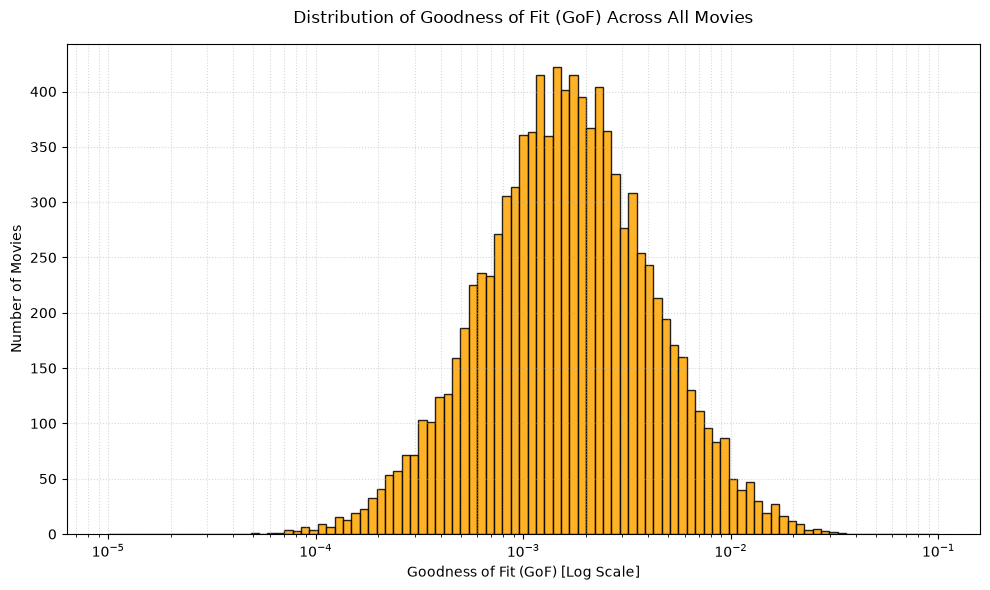

In [32]:
gof_values = df_results["GOF"].values

min_log = np.floor(np.log10(gof_values.min()))
max_log = np.ceil(np.log10(gof_values.max()))
log_bins = np.logspace(min_log, max_log, 100)

fig, ax = plt.subplots(figsize=(10, 6), dpi=100)

ax.hist(
    gof_values,
    bins=log_bins,
    edgecolor="black",
    linewidth=1.0,
    alpha=0.85,
    color="orange"
)

ax.set_xscale("log")
ax.set_title("Distribution of Goodness of Fit (GoF) Across All Movies", fontsize=12, pad=15)
ax.set_xlabel("Goodness of Fit (GoF) [Log Scale]", fontsize=10)
ax.set_ylabel("Number of Movies", fontsize=10)
ax.grid(True, which="both", linestyle=":", alpha=0.5)

plt.tight_layout()


In [ ]:
prediction_results = []

for movie_id, data in movie_time_series.items():
    t_vals = data["t"]
    y_vals = data["y"]
    n_total = len(y_vals)
    
    
    if n_total < 10:                    # Makinf sure we have atleast a few reviews, should be no problem for top 500
        continue
    
    split_idx = n_total // 2
    
    t_train, y_train = t_vals[:split_idx], y_vals[:split_idx]
    t_test, y_test = t_vals[split_idx:], y_vals[split_idx:]
    
    if len(t_train) < 3 or len(t_test) < 3:
        continue

    best = get_best_fit(t_train, y_train, models, one_par_wrapper, two_par_wrapper)
    
    if best["gof"] is None or best["name"].startswith("Unclassified"):
        continue

    best_model_name = best["name"]
    best_lam = best["lam"]
    best_k = best["k"]

    S0_global = y_vals[0] if y_vals[0] > 0 else 1e-5
    
    if best_model_name in ["Mod. Neg. Exponential", "Mod. Gompertz"]:
        wrapped_func_test = two_par_wrapper(models[best_model_name], S0_global)
        y_pred_test = wrapped_func_test(t_test, best_lam, best_k)
    else:
        wrapped_func_test = one_par_wrapper(models[best_model_name], S0_global)
        y_pred_test = wrapped_func_test(t_test, best_lam)

    test_mer = np.mean(np.abs(y_test - y_pred_test) / (y_test + 1.0))
    test_msc = np.sum((y_test - y_pred_test) ** 2)

    prediction_results.append({
        "movieId": movie_id,
        "title": data["title"],
        "selected_model": best_model_name,
        "test_MER": test_mer,
        "test_MSC": test_msc,
        "is_accurate": test_mer <= 0.05
    })

predictions_df = pd.DataFrame(prediction_results)

if not predictions_df.empty:
    success_rate = predictions_df['is_accurate'].mean() * 100
    print(f"\nPercentage of movies predicted with <= 5% MER on the second half: {success_rate:.2f}%")

/tmp/ipykernel_163229/472703222.py:26: RuntimeWarning: overflow encountered in exp
  return M * np.exp(-np.log(M / S0) * np.exp(-lam * t)) + k * t
/tmp/ipykernel_163229/1005548038.py:32: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, _ = curve_fit(wrapped_func, t_train, y_train, p0=p0, method="lm", maxfev=5000)
/tmp/ipykernel_163229/472703222.py:26: RuntimeWarning: overflow encountered in multiply
  return M * np.exp(-np.log(M / S0) * np.exp(-lam * t)) + k * t


   movieId                    title         selected_model  test_MER  \
0     2769        Yards, The (2000)          Mod. Gompertz  0.415314   
1     3177       Next Friday (2000)  Mod. Neg. Exponential  0.101663   
2     3190         Supernova (2000)  Mod. Neg. Exponential  0.049709   
3     3225       Down to You (2000)  Mod. Neg. Exponential  0.103016   
4     3239  Isn't She Great? (2000)  Mod. Neg. Exponential  0.442780   

     test_MSC  is_accurate_5_pct  
0  479.464190              False  
1   56.572185              False  
2   13.396448               True  
3   29.253043              False  
4  220.203168              False  

Percentage of movies predicted with <= 5% MER on the second half: 17.38%


Movies by Popularity Class:
popularity_bin
Very Unpopular (<100)    3582
Unpopular (100-999)      4284
Successful (1k-9.9k)     1797
Popular (10k-99.9k)       337
Very Popular (100k+)        0
Name: count, dtype: int64


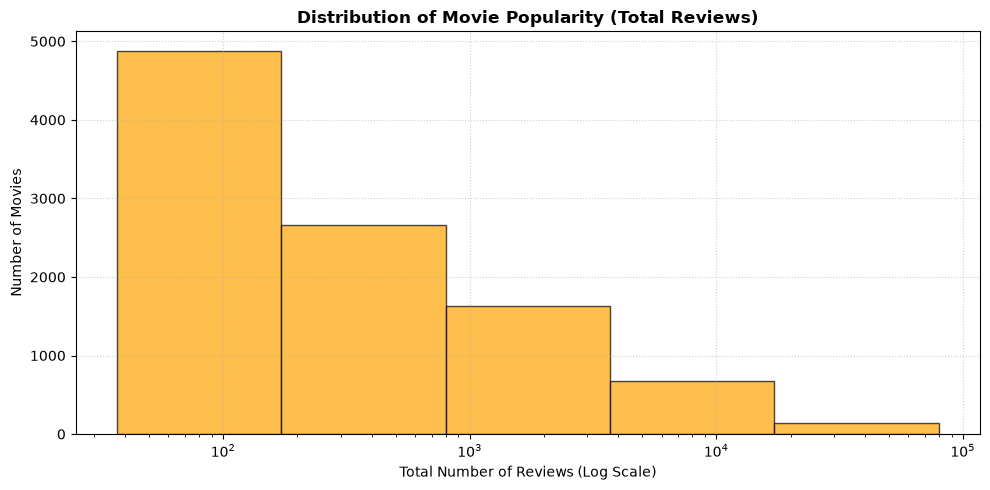

In [28]:
bin_edges = [0, 100, 1000, 10000, 100000, float("inf")]
bin_labels = [
    "Very Unpopular (<100)",
    "Unpopular (100-999)",
    "Successful (1k-9.9k)",
    "Popular (10k-99.9k)",
    "Very Popular (100k+)",
]

df_results["popularity_bin"] = pd.cut(
    df_results["total_reviews"], bins=bin_edges, labels=bin_labels, right=False
)

print("Movies by Popularity Class:")
print(df_results["popularity_bin"].value_counts(sort=False))

fig, ax = plt.subplots(figsize=(10, 5), dpi=100)

counts, edges, patches = ax.hist(
    df_results["total_reviews"].dropna(),
    bins=np.logspace(
        np.log10(max(1, df_results["total_reviews"].min())),
        np.log10(df_results["total_reviews"].max()),
        6,
    ),
    color="orange",
    edgecolor="black",
    alpha=0.7,
)

ax.set_xscale("log")
ax.set_title("Distribution of Movie Popularity (Total Reviews)", fontsize=12, fontweight="bold")
ax.set_xlabel("Total Number of Reviews (Log Scale)", fontsize=10)
ax.set_ylabel("Number of Movies", fontsize=10)
ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

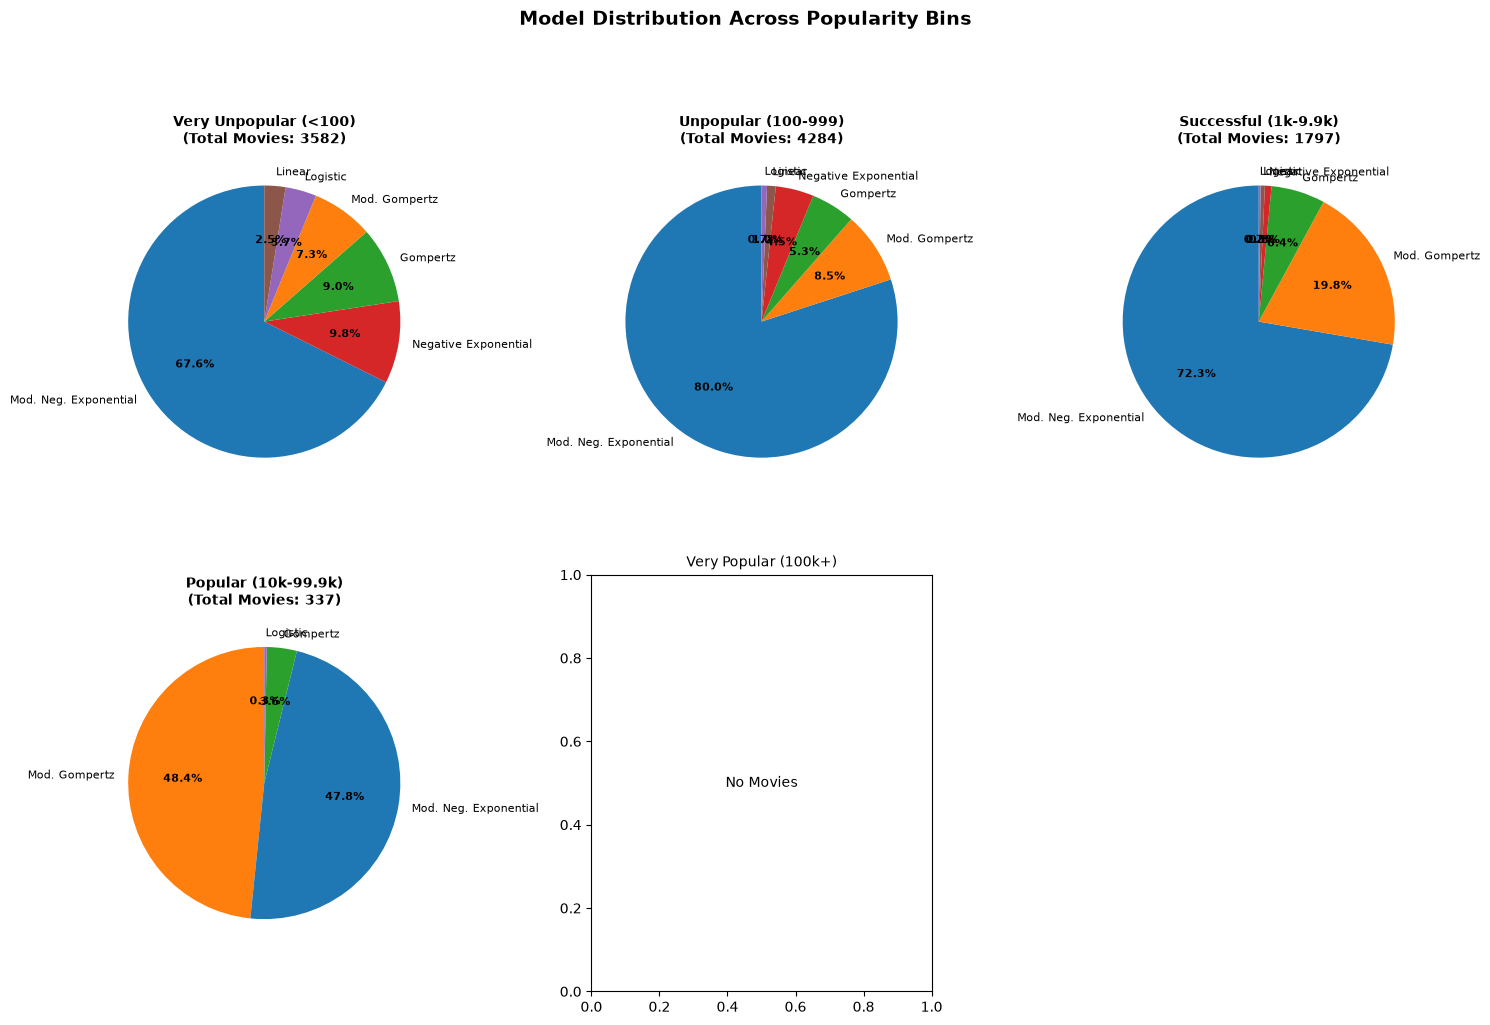

In [29]:
plot_df = df_results.dropna(subset=["popularity_bin", "best_model"])

bins_with_data = plot_df["popularity_bin"].dtype.categories

num_bins = len(bins_with_data)
if num_bins > 0:
    unique_models = plot_df["best_model"].unique()
    color_palette = plt.get_cmap("tab10").colors
    model_color_map = {
        model: color_palette[i % len(color_palette)] 
        for i, model in enumerate(unique_models)
    }

    cols = 3
    rows = (num_bins + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 5))
    if num_bins == 1:
        axes = np.array([axes])
    else:
        axes = axes.flatten()

    for idx, bin_name in enumerate(bins_with_data):
        ax = axes[idx]
        
        sub_df = plot_df[plot_df["popularity_bin"] == bin_name]
        model_counts = sub_df["best_model"].value_counts()
        
        if not model_counts.empty:
            bin_colors = [model_color_map[model] for model in model_counts.index]
            
            wedges, texts, autotexts = ax.pie(
                model_counts.values, 
                labels=model_counts.index, 
                colors=bin_colors,
                autopct='%1.1f%%', 
                startangle=90,
                textprops=dict(fontsize=8)
            )
            plt.setp(autotexts, size=8, weight="bold")
            ax.set_title(f"{bin_name}\n(Total Movies: {len(sub_df)})", fontsize=10, fontweight="bold")
        else:
            ax.text(0.5, 0.5, "No Movies", horizontalalignment='center', verticalalignment='center', transform=ax.transAxes)
            ax.set_title(f"{bin_name}", fontsize=10)

    for j in range(num_bins, len(axes)):
        axes[j].axis('off')

    plt.suptitle("Model Distribution Across Popularity Bins", fontsize=14, fontweight="bold", y=1.02)
    plt.tight_layout()
else:
    print("No data available in popularity bins to plot.")

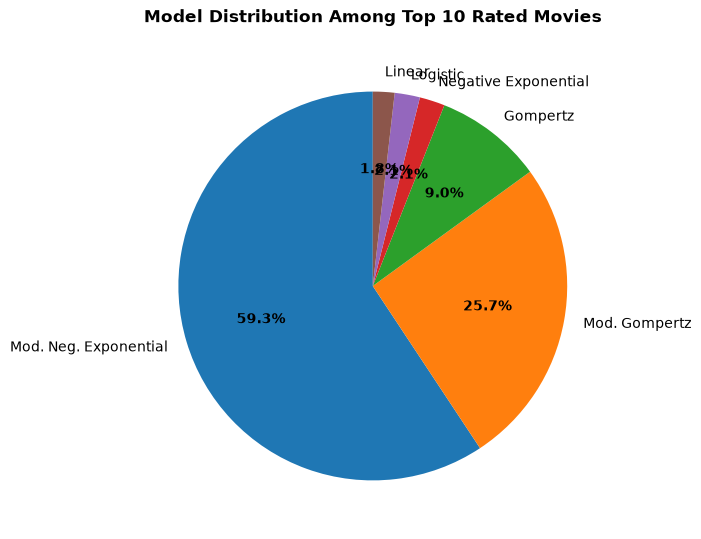

In [ ]:
top_rated = df_results.sort_values(by="avg_rating", ascending=False).head(int(TOP_N*0.1))

model_counts = top_rated["best_model"].value_counts()

fig, ax = plt.subplots(figsize=(7, 7), dpi=100)

wedges, texts, autotexts = ax.pie(
    model_counts.values,
    labels=model_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    textprops=dict(fontsize=10)
)

plt.setp(autotexts, size=10, weight="bold")
ax.set_title("Model Distribution Among Top 10% Rated Movies", fontsize=12, fontweight="bold", pad=15)
plt.tight_layout()



# Citattions

1. > F. Maxwell Harper and Joseph A. Konstan. 2015. The MovieLens Datasets: History and Context. ACM Transactions on Interactive Intelligent Systems (TiiS) 5, 4: 19:1–19:19. <https://doi.org/10.1145/2827872>

2. Cedric Richier, Eitan Altman, Rachid El-Azouzi, Tania Jimenez, Georges Linarès, et al.. Bio-Inspired
Models for Characterizing YouTube Viewcount. IEEE/ACM International Conference on Advances
in Social Networks Analysis and Mining (ASONAM 2014), Aug 2014, Beijing, China. pp.297-305,
⟨10.1109/ASONAM.2014.6921600⟩. ⟨hal-01011069


# Experiments below

In [99]:

def find_saddle_(t_vals, y_vals, window_size=0.05, sensitivity=0.15):
    n = len(t_vals)
    slopes = []
    right_edges = []

    j = 0
    for i in range(n):

        while j < n and (t_vals[j] - t_vals[i]) < window_size:
            j +=1
        
        if j == n:
            break

        dy = y_vals[j] - y_vals [i]
        dt = t_vals[j] - t_vals[i]

        if dt > 0:
            slopes.append(dy / dt)
            right_edges.append(j)

    if not slopes:
        return None


    slopes = np.array(slopes)
    min_slope_idx = np.argmin(slopes)
    min_slope = slopes[min_slope_idx]

    avg_global_slope = (y_vals[-1] - y_vals[0]) / (t_vals[-1] - t_vals[0])      # we go thorugh all the slopes and if it hasnt increased tooo much we jsut go further until it really increases
    threshold = min_slope + (sensitivity * avg_global_slope)

    best_i = min_slope_idx
    for k in range(min_slope_idx, len(slopes)):
        if slopes[k] > threshold:
            break 
        best_i = k  
        
    hinge_idx = right_edges[best_i]
    return hinge_idx


# Split all of our movies with our algo

split_indices = []
for _, row in df_results.iterrows():
    movie_id = row["movieId"]

    if movie_id in movie_time_series:
        data = movie_time_series[movie_id]
        t_vals = data["t"]
        y_vals = data["y"]

        hinge_idx = find_saddle_(t_vals, y_vals, window_size=0.05, sensitivity=0.15)

        if hinge_idx is not None:
            split_indices.append(hinge_idx)
        else:
            split_indices.append(np.nan)

    else:
        split_indices.append(np.nan)

df_results["split_idx"] = split_indices

print(df_results[["movieId", "title", "best_model", "GOF", "split_idx"]].head(10))

   movieId                         title             best_model       GOF  \
0     3273               Scream 3 (2000)  Mod. Neg. Exponential  0.001098   
1     3275   Boondock Saints, The (2000)          Mod. Gompertz  0.001298   
2     3285             Beach, The (2000)  Mod. Neg. Exponential  0.001881   
3     3300            Pitch Black (2000)  Mod. Neg. Exponential  0.001706   
4     3301  Whole Nine Yards, The (2000)  Mod. Neg. Exponential  0.000674   
5     3317            Wonder Boys (2000)  Mod. Neg. Exponential  0.000155   
6     3354        Mission to Mars (2000)  Mod. Neg. Exponential  0.001786   
7     3408        Erin Brockovich (2000)  Mod. Neg. Exponential  0.000934   
8     3409      Final Destination (2000)  Mod. Neg. Exponential  0.002087   
9     3481          High Fidelity (2000)  Mod. Neg. Exponential  0.000571   

   split_idx  
0       8724  
1        492  
2       5572  
3       7380  
4       9887  
5       7865  
6       8402  
7      16487  
8       5342  
9 

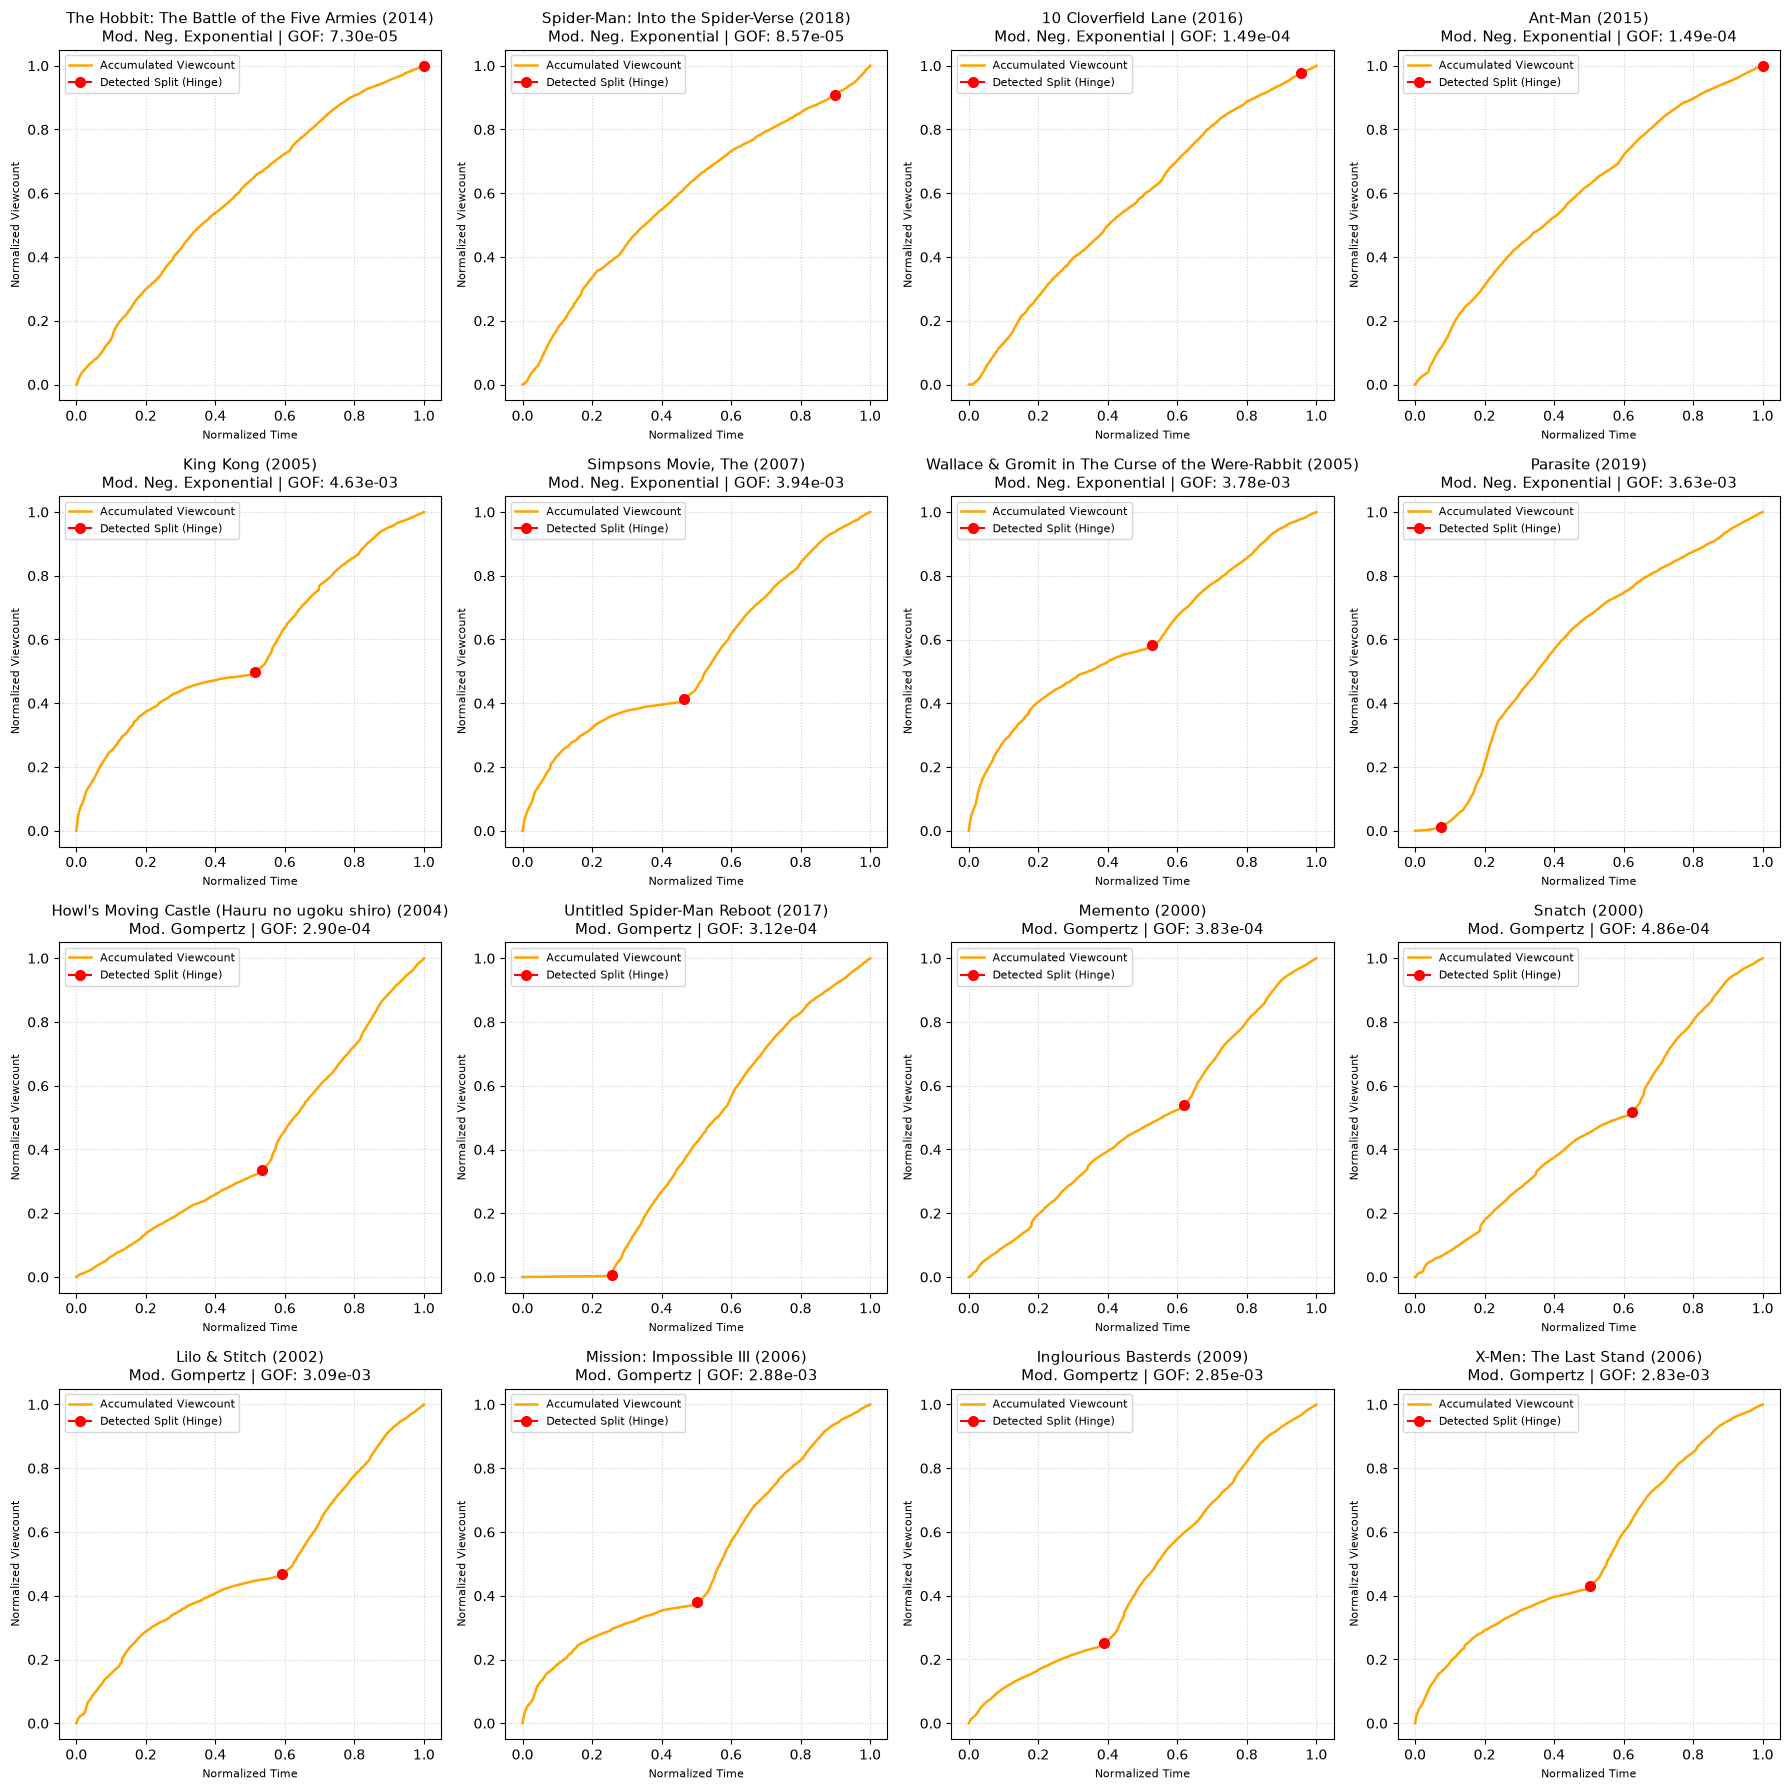

In [100]:
neg_exponential_best = (
    df_results[df_results["best_model"] == "Mod. Neg. Exponential"]
    .sort_values(by="GOF", ascending = True)       # Lowest GOF best fit
    .head(4)
)

neg_exponential_worst = (
    df_results[df_results["best_model"] == "Mod. Neg. Exponential"]
    .sort_values(by="GOF", ascending = False)       # Lowest GOF best fit
    .head(4)
)

mod_gom_best = (
    df_results[df_results["best_model"] == "Mod. Gompertz"]
    .sort_values(by="GOF", ascending = True)       # Lowest GOF best fit
    .head(4)
)

mod_gom_worst = (
    df_results[df_results["best_model"] == "Mod. Gompertz"]
    .sort_values(by="GOF", ascending = False)       # Lowest GOF best fit
    .head(4)
)

df = pd.concat([
    neg_exponential_best, 
    neg_exponential_worst, 
    mod_gom_best, 
    mod_gom_worst
], ignore_index=True)

fig, axes = plt.subplots(4, 4, figsize=(18, 18))
axes = axes.flatten()

for idx, (_, row) in enumerate(df.iterrows()):
    movie_id = row["movieId"]
    model_name = row["best_model"]
    title = row["title"]
    split_idx = row["split_idx"]

    data = movie_time_series[movie_id]
    t_vals = data["t"]
    y_vals = data["y"]

    ax = axes[idx]
    
    # 1. Plot the actual accumulated viewcount
    ax.plot(t_vals, y_vals, label="Accumulated Viewcount", color="orange", linewidth=1.8)

    # 2. Plot a red dot at the detected split point (if a valid split exists)
    if pd.notna(split_idx):
        s_idx = int(split_idx)
        ax.plot(t_vals[s_idx], y_vals[s_idx], marker="o", color="red", 
                label="Detected Split (Hinge)", markersize=7, zorder=5)

    # Formatting
    ax.set_title(f"{title}\n{model_name} | GOF: {row['GOF']:.2e}", fontsize=11)
    ax.set_xlabel("Normalized Time", fontsize=8)
    ax.set_ylabel("Normalized Viewcount", fontsize=8)
    ax.legend(fontsize=8)
    ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

After we split our accumulated view counts into two we can then run individual fitting on both of the series.

In [116]:
def fit_segment(t_seg, y_seg):
    # Check if segment is too small to fit anything
    if len(y_seg) < 3:
        return "Too Short", None, None, float("inf"), float("inf"), float("inf")
        
    S0_seg = y_seg[0] if y_seg[0] > 0 else 1e-5
    n = len(y_seg)
    segment_candidates = []
    
    t_relative = t_seg - t_seg[0]

    for model_name, model_func in models.items():
        try:
            if model_name == "Mod. Neg. Exponential" or model_name == "Mod. Gompertz":
                wrapped_func = two_par_wrapper(model_func, S0_seg)
                p0 = [1.0, 0.1]     # initial guess for lam and k
                p = 2

                # Ensure we have more data points than parameters
                if n <= p:
                    continue

                popt, pcov = curve_fit(wrapped_func, t_relative, y_seg, p0=p0, method="lm", maxfev=5000)
                opt_lam, opt_k = popt
                y_pred = wrapped_func(t_relative, opt_lam, opt_k)

            else:
                wrapped_func = one_par_wrapper(model_func, S0_seg)
                p0 = [1.0]          # initial guess for lam
                p = 1

                popt, pcov = curve_fit(wrapped_func, t_relative, y_seg, p0=p0, method="lm", maxfev=5000)
                opt_lam = popt[0] if isinstance(popt, np.ndarray) else popt
                opt_k = None                            # We dont optimize it for these models
                y_pred = wrapped_func(t_relative, opt_lam)

            mer = np.mean(np.abs(y_seg - y_pred) / (y_seg + 1.0))
            msc = np.sum((y_pred - y_seg) ** 2)

            df = n - p
            gof = (1.0 / df) * msc if df > 0 else float("inf")

            segment_candidates.append({
                "name": model_name, "gof": gof, "msc": msc,
                "lam": opt_lam, "k": opt_k, "mer": mer
            })
        except Exception:
            # Skip models that fail to converge or throw dimension errors
            continue
        
    if not segment_candidates:
        return "Failed", None, None, float("inf"), float("inf"), float("inf")
        
    best_seg = min(segment_candidates, key=lambda x: x["gof"])

    return best_seg["name"], best_seg["lam"], best_seg["k"], best_seg["gof"], best_seg["msc"], best_seg["mer"]


# --- Your main loop with safety validation ---
results = []
for movie_id, data in movie_time_series.items():
    t_vals = data["t"]
    y_vals = data["y"]
    n_total = len(y_vals)

    row_match = df_results[df_results["movieId"] == movie_id]
    if row_match.empty or pd.isna(row_match.iloc[0]["split_idx"]):
        continue
        
    split_idx = int(row_match.iloc[0]["split_idx"])

    t1, y1 = t_vals[:split_idx], y_vals[:split_idx]
    t2, y2 = t_vals[split_idx:], y_vals[split_idx:]

    # Skip if either segment is too tiny to fit curves
    if len(y1) < 3 or len(y2) < 3:
        continue

    m1_name, m1_lam, m1_k, m1_gof, m1_msc, m1_mer = fit_segment(t1, y1)
    m2_name, m2_lam, m2_k, m2_gof, m2_msc, m2_mer = fit_segment(t2, y2)

    results.append({
        "movieId": movie_id,
        "title": data["title"],
        "split_idx": split_idx,
        "split_t": t_vals[split_idx],

        "P1_model": m1_name,
        "P1_lam": m1_lam,
        "P1_k": m1_k,
        "P1_GOF": m1_gof,

        "P2_model": m2_name,
        "P2_lam": m2_lam,
        "P2_k": m2_k,
        "P2_GOF": m2_gof,
    })

df_two_phase_results = pd.DataFrame(results)
print(df_two_phase_results.head())

/tmp/ipykernel_54383/52891330.py:23: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(wrapped_func, t_relative, y_seg, p0=p0, method="lm", maxfev=5000)
/tmp/ipykernel_54383/418221266.py:28: RuntimeWarning: overflow encountered in exp
  return M * np.exp(-np.log(M / S0) * np.exp(-lam * t)) + k * t
/tmp/ipykernel_54383/418221266.py:28: RuntimeWarning: overflow encountered in multiply
  return M * np.exp(-np.log(M / S0) * np.exp(-lam * t)) + k * t
/tmp/ipykernel_54383/52891330.py:32: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(wrapped_func, t_relative, y_seg, p0=p0, method="lm", maxfev=5000)


   movieId                         title  split_idx   split_t  \
0     3275   Boondock Saints, The (2000)        492  0.105229   
1     3285             Beach, The (2000)       5572  0.635501   
2     3300            Pitch Black (2000)       7380  0.647725   
3     3301  Whole Nine Yards, The (2000)       9887  0.999438   
4     3408        Erin Brockovich (2000)      16487  0.638894   

                P1_model    P1_lam      P1_k    P1_GOF              P2_model  \
0          Mod. Gompertz  6.178406  0.289001  0.000001         Mod. Gompertz   
1  Mod. Neg. Exponential  2.621179 -0.305908  0.000256         Mod. Gompertz   
2  Mod. Neg. Exponential  2.133654 -0.241218  0.000101         Mod. Gompertz   
3  Mod. Neg. Exponential  1.851443  0.135338  0.000674  Negative Exponential   
4  Mod. Neg. Exponential  2.902082 -0.155734  0.000226         Mod. Gompertz   

        P2_lam      P2_k        P2_GOF  
0     0.975678  0.919278  4.234734e-04  
1     5.969269  0.146956  2.944759e-05  
2    

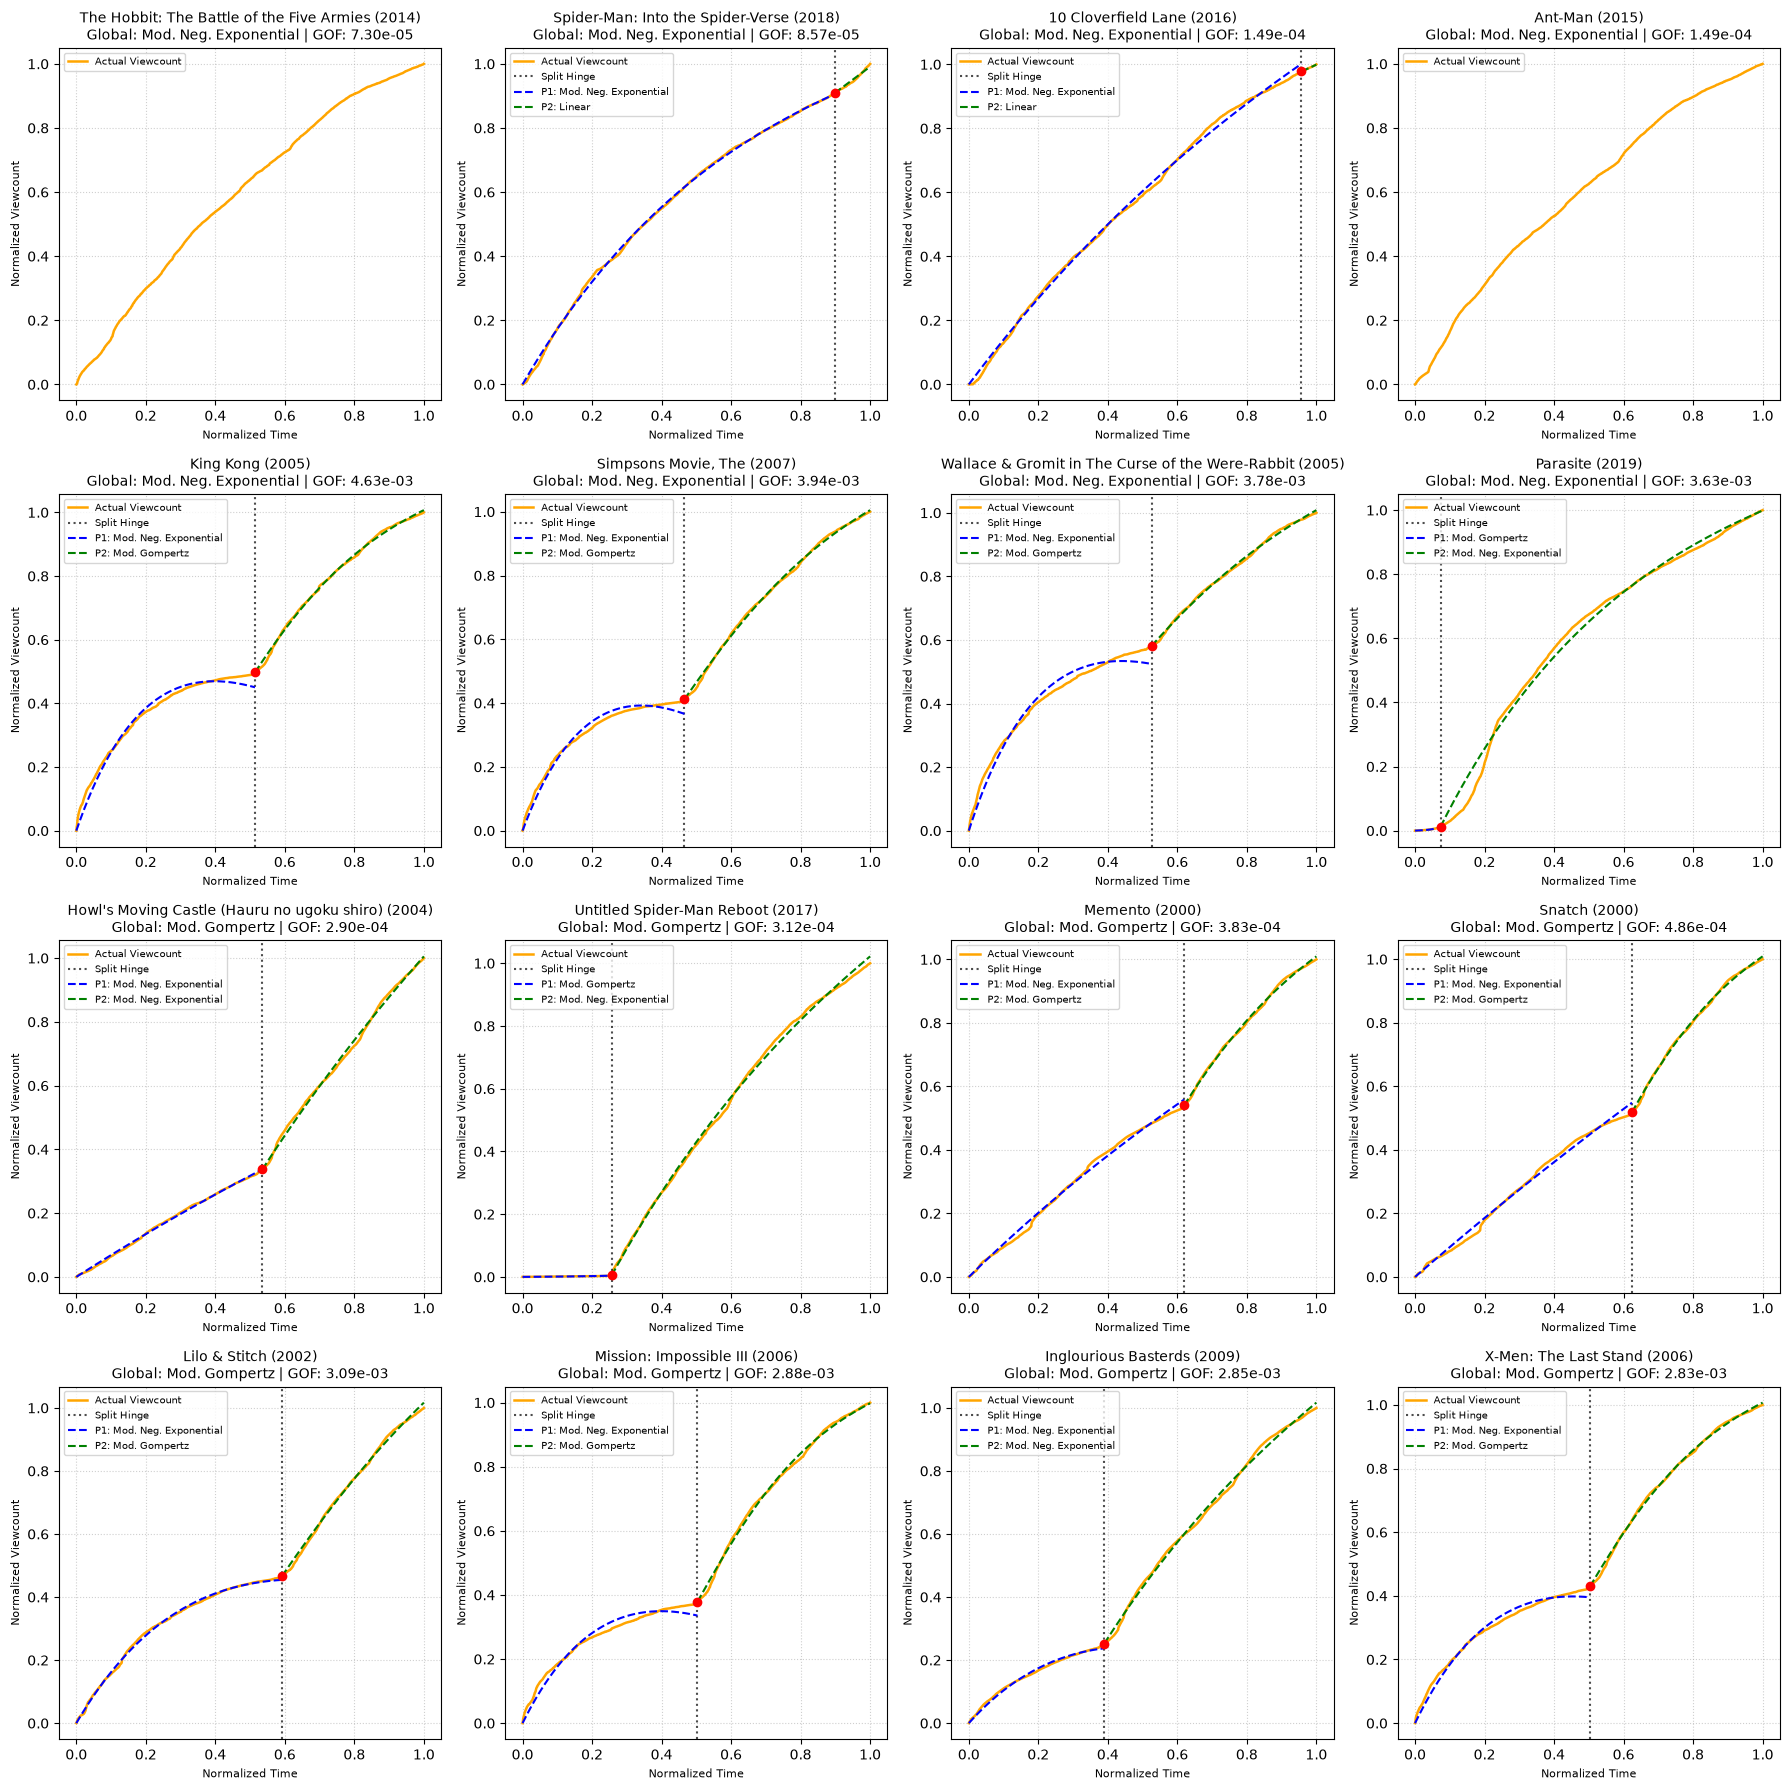

In [118]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Re-create your exact original 16 subset movies using df_results
neg_exponential_best = (
    df_results[df_results["best_model"] == "Mod. Neg. Exponential"]
    .sort_values(by="GOF", ascending=True)       
    .head(4)
)

neg_exponential_worst = (
    df_results[df_results["best_model"] == "Mod. Neg. Exponential"]
    .sort_values(by="GOF", ascending=False)       
    .head(4)
)

mod_gom_best = (
    df_results[df_results["best_model"] == "Mod. Gompertz"]
    .sort_values(by="GOF", ascending=True)       
    .head(4)
)

mod_gom_worst = (
    df_results[df_results["best_model"] == "Mod. Gompertz"]
    .sort_values(by="GOF", ascending=False)       
    .head(4)
)

df_subset = pd.concat([
    neg_exponential_best, 
    neg_exponential_worst, 
    mod_gom_best, 
    mod_gom_worst
], ignore_index=True)

# 2. Plotting grid (4x4)
fig, axes = plt.subplots(4, 4, figsize=(18, 18))
axes = axes.flatten()

for idx, (_, row) in enumerate(df_subset.iterrows()):
    if idx >= len(axes):
        break
        
    movie_id = row["movieId"]
    title = row["title"]
    global_model = row["best_model"]
    global_gof = row["GOF"]

    # Match this movie in your two-phase results DataFrame
    two_phase_match = df_two_phase_results[df_two_phase_results["movieId"] == movie_id]
    
    ax = axes[idx]
    
    # Retrieve data
    data = movie_time_series[movie_id]
    t_vals = data["t"]
    y_vals = data["y"]

    # Plot full actual view accumulation
    ax.plot(t_vals, y_vals, label="Actual Viewcount", color="orange", linewidth=1.8)

    if not two_phase_match.empty:
        tp_row = two_phase_match.iloc[0]
        split_idx = int(tp_row["split_idx"])
        split_t = tp_row["split_t"]

        # Phase details
        m1_name = tp_row["P1_model"]
        m1_lam = tp_row["P1_lam"]
        m1_k = tp_row["P1_k"]
        
        m2_name = tp_row["P2_model"]
        m2_lam = tp_row["P2_lam"]
        m2_k = tp_row["P2_k"]

        # Plot vertical split line and hinge dot
        ax.axvline(x=split_t, color="black", linestyle=":", alpha=0.7, label="Split Hinge")
        ax.plot(t_vals[split_idx], y_vals[split_idx], marker="o", color="red", markersize=6, zorder=5)

        # --- Predict and Plot Phase 1 ---
        if pd.notna(m1_lam) and m1_name in models:
            t1 = t_vals[:split_idx]
            y1 = y_vals[:split_idx]
            if len(y1) > 0:
                S0_1 = y1[0] if y1[0] > 0 else 1e-5
                t1_rel = t1 - t1[0]
                
                if m1_name in ["Mod. Neg. Exponential", "Mod. Gompertz"]:
                    func1 = two_par_wrapper(models[m1_name], S0_1)
                    y_pred1 = func1(t1_rel, m1_lam, m1_k)
                else:
                    func1 = one_par_wrapper(models[m1_name], S0_1)
                    y_pred1 = func1(t1_rel, m1_lam)
                    
                ax.plot(t1, y_pred1, label=f"P1: {m1_name}", color="blue", linestyle="dashed", linewidth=1.5)

        # --- Predict and Plot Phase 2 ---
        if pd.notna(m2_lam) and m2_name in models:
            t2 = t_vals[split_idx:]
            y2 = y_vals[split_idx:]
            if len(y2) > 0:
                S0_2 = y2[0] if y2[0] > 0 else 1e-5
                t2_rel = t2 - t2[0]
                
                if m2_name in ["Mod. Neg. Exponential", "Mod. Gompertz"]:
                    func2 = two_par_wrapper(models[m2_name], S0_2)
                    y_pred2 = func2(t2_rel, m2_lam, m2_k)
                else:
                    func2 = one_par_wrapper(models[m2_name], S0_2)
                    y_pred2 = func2(t2_rel, m2_lam)
                    
                ax.plot(t2, y_pred2, label=f"P2: {m2_name}", color="green", linestyle="dashed", linewidth=1.5)

    # Formatting
    ax.set_title(f"{title}\nGlobal: {global_model} | GOF: {global_gof:.2e}", fontsize=10)
    ax.set_xlabel("Normalized Time", fontsize=8)
    ax.set_ylabel("Normalized Viewcount", fontsize=8)
    ax.legend(fontsize=7, loc="upper left")
    ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

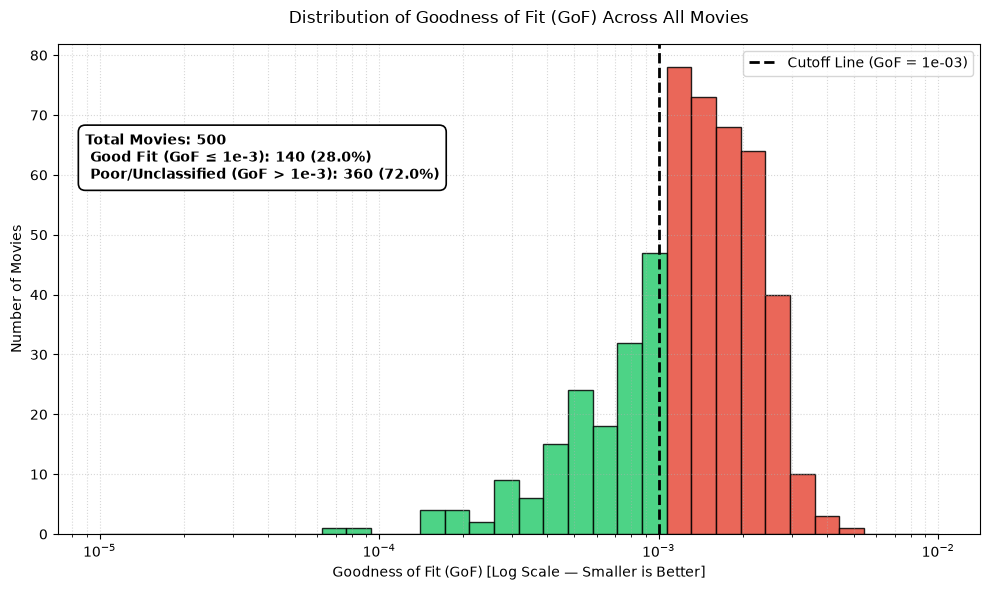

In [36]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Filter out unclassified movies (NaN/None GOF)
valid_df = df_results.dropna(subset=["GOF"]).copy()
gof_values = valid_df["GOF"].values

# 2. Define the threshold line for a "Good Fit" vs "Poor Fit"
# In paper benchmarks (Table III/IV), reliable fits stay below ~1e-3 (0.001)
THRESHOLD_GOF = 1e-3

# Count good vs bad/unclassified movies
n_good = len(valid_df[valid_df["GOF"] <= THRESHOLD_GOF])
n_total = len(df_results)
n_bad = n_total - n_good

# 3. Create logarithmic bins across the GoF range
min_log = np.floor(np.log10(gof_values.min()))
max_log = np.ceil(np.log10(gof_values.max()))
log_bins = np.logspace(min_log, max_log, 35)

# 4. Plot Histogram
fig, ax = plt.subplots(figsize=(10, 6), dpi=100)

n, bins, patches = ax.hist(
    gof_values,
    bins=log_bins,
    edgecolor="black",
    linewidth=1.0,
    alpha=0.85
)

# Color-code bars: Green for Good Fit (<= 1e-3), Red for Marginal/Poor Fit (> 1e-3)
for patch, left_edge in zip(patches, bins[:-1]):
    if left_edge < THRESHOLD_GOF:
        patch.set_facecolor("#2ecc71")  # Green
    else:
        patch.set_facecolor("#e74c3c")  # Red

# 5. Draw Threshold Line
ax.axvline(
    THRESHOLD_GOF,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Cutoff Line (GoF = {THRESHOLD_GOF:.0e})"
)

# 6. Formatting & Axes
ax.set_xscale("log")
ax.set_title("Distribution of Goodness of Fit (GoF) Across All Movies", fontsize=12, pad=15)
ax.set_xlabel("Goodness of Fit (GoF) [Log Scale — Smaller is Better]", fontsize=10)
ax.set_ylabel("Number of Movies", fontsize=10)

# 7. Summary Overlay Box
summary_text = (
    f"Total Movies: {n_total}\n"
    f" Good Fit (GoF ≤ 1e-3): {n_good} ({n_good/n_total*100:.1f}%)\n"
    f" Poor/Unclassified (GoF > 1e-3): {n_bad} ({n_bad/n_total*100:.1f}%)"
)

ax.text(
    0.03, 0.82,
    summary_text,
    transform=ax.transAxes,
    fontsize=10,
    fontweight="bold",
    verticalalignment="top",
    bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="black", lw=1.2)
)

ax.grid(True, which="both", linestyle=":", alpha=0.5)
ax.legend(loc="upper right", fontsize=10)

plt.tight_layout()
plt.show()

To investigate this further i calssified the movies based on overall low MER which suggest a rather good fit, but a rather high GoF, to try an capture all the movies which exhibut this growth platue, growth platue metric.
